---
title: "Eley-Rideal kinetics: the impact rate law, and the case that the name is wrong"
description: "The gas-collision (impact) rate law contrasted with Langmuir-Hinshelwood kinetics imported from C1.1: every printed limit derived, a dimensionally inconsistent printed maximum condition reported, the identifiability window root-found, and the founding 1947 LHHW dataset shown to reject the impact form for exactly one reason, its hydrogen-pressure span."
categories: [sec:C, struct:S1, tier:T0, data:tier6, phase:gas, phase:gas-solid, phase:liquid-solid]
date: 2026-08-08
---

# Eley-Rideal kinetics: the impact rate law, and the case that the name is wrong

**Catalog ID:** `C1.2` · **Structures:** `S1` (pointwise rate algebra) · **Tier:** T0

The mechanism in which a gas-phase molecule reacts by direct collision with a
chemisorbed one is called the **Eley-Rideal (E-R) mechanism** in surface
science, catalysis and astronomy. The source this page is built from, Prins,
*Topics in Catalysis* **61** (2018) 714-721, argues from the primary
literature that the name is wrong twice over: the colliding-molecule
mechanism was proposed by **Langmuir in 1922**, and what **Eley and Rideal
actually studied** (1940-41) is a different mechanism, a chemisorbed atom
reacting with a molecule held in a *van der Waals layer*, in thermal
equilibrium with the surface. Prins therefore writes the colliding-molecule
rate law as the **Langmuir-Rideal (L-R)** law.

This page builds that rate law, derives every limit the paper states for it,
contrasts it with the Langmuir-Hinshelwood (L-H) law whose derivation is
**imported from the published page `C1.1`** (Hougen and Watson's 1947 codimer
estimation), quantifies when the two laws can and cannot be told apart, and
reports one printed defect: the paper's maximum condition "$c_A = K_A$" is
dimensionally inconsistent with its own Eq. (3a). **The paper prints no
measurement, no table and no figure**, so everything quantitative here is
analytical or a labelled numerical experiment on `C1.1`'s fitted constants.
The page claims no experimental validation, because none is possible from
this source.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.23"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C1.2-eley-rideal"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip. sympy is
# used for the derivations. pymrm contributes find_roots, and newton on
# NumJac((1, 1)) as an independent second route (see "What pymrm adds").
import subprocess
try:
    import sympy as sp
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sympy"])
    import sympy as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import least_squares, minimize, minimize_scalar
from pymrm import newton, NumJac
from pymrm.checks import find_roots
from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
claims = Claims(PAGE.split("-")[0])
PAGE_C11 = "C1.1-lhhw-hougen-watson"   # the borrowed Hougen and Watson tables, and its claims
BREAK = []   # (injected defect, claim, clean value, broken value, caught)

# Okabe-Ito, assigned in a fixed order and never cycled:
#   0 Langmuir-Hinshelwood  1 impact (Langmuir-Rideal)  2 non-competing L-H, Eq. (3c)  3 window misfit
COL = {"lh": "#0072B2", "lr": "#D55E00", "nc": "#009E73", "win": "#CC79A7"}


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def brk_all(row, got):
    """Break row for every claim of a group: ``got`` maps claim names to the values the
    helper returns when it is called with the defect injected."""
    for name, v in got.items():
        if name in claims.metrics:
            brk(row, name, v)


def brk_helper(row, helper, names, *args, **kw):
    """Break rows from ``helper(*args, **kw)``. Where the defect leaves no root on the whole
    physical range (a ``find_roots`` scan in the helper raises ``ValueError``), every claim in
    ``names`` records nan, and the row says so."""
    try:
        got = helper(*args, **kw)
    except ValueError as exc:
        got = {n: float("nan") for n in names}
        row = f"{row} (no admissible root on the whole range: {exc})"
    return brk_all(row, got)


def say(text, **kw):
    """Put computed numbers into prose: ``@@name@@`` is replaced by ``kw['name']``."""
    for k, v in kw.items():
        text = text.replace(f"@@{k}@@", str(v))
    assert "@@" not in text, "unfilled placeholder"
    display(Markdown(text))


def one_root(f, lo, hi, n=64, log=False, xtol=1e-12):
    """The single root of ``f`` on the physical range ``[lo, hi]`` by pymrm's
    ``find_roots``; raises ``ValueError`` unless exactly one sign change is found."""
    found = find_roots(f, lo, hi, n_scan=n, log=log, xtol=xtol)
    if len(found["roots"]) != 1:
        raise ValueError(f"expected one root on [{lo:.4g}, {hi:.4g}]: {found['message']}")
    return found["roots"][0]

## Background

**The source, precisely.** The document on disk is Prins, R., "Eley-Rideal,
the Other Mechanism", *Topics in Catalysis* **61** (2018) 714-721,
doi:10.1007/s11244-018-0948-8, single author (ETH Zürich), labelled
ORIGINAL PAPER but historical and terminological in content. It is
**born-digital** (the PDF carries no page scans, only decorative logos), so
renders are clean vector rasterisations; every numeric and every equation
used here was nevertheless read from a cropped render of its own page region,
never from the text layer alone. The catalogue row for C1.2 had **no
reference at all**; this paper was supplied from disk and identified from its
own title page.

**What the paper argues.** In 1922 Langmuir suggested three mechanisms for
reactions at surfaces, quoted by Prins (p. 714) from *Trans. Faraday Soc.*
**17**, 607:

> "1. A reaction which takes place at the surface of a catalyst may occur by
> interaction between molecules or atoms adsorbed in adjacent spaces on the
> surface, 2. or it may occur between an adsorbed film and the atoms of the
> underlying solid, 3. or again, it may take place directly as a result of a
> collision between a gas molecule and an adsorbed molecule or atom on the
> surface."

Prins maps these to today's names: the first is the **Langmuir-Hinshelwood
mechanism** (gallery page `C1.1`), the second "constitutes the first step in a
Mars-van Krevelen mechanism" (gallery page `C1.3`), and the third, the
subject of this page, "is usually, but incorrectly as we will see, called
Eley-Rideal mechanism". The paper's thesis, stated in its abstract:

> "Therefore, the reaction between a chemisorbed molecule and a gaseous
> colliding molecule should be called Langmuir-Rideal reaction rather than
> Eley-Rideal reaction, as it is often called in surface science, catalysis
> and astronomy."

What Eley and Rideal themselves studied (para-ortho H₂ conversion and H₂/D₂
exchange on tungsten) involved a chemisorbed H atom and a **physisorbed** H₂
molecule. Prins reserves "the real E-R mechanism" for that, and notes the
IUPAC Gold Book already defines the Langmuir-Rideal name for the collision
mechanism (p. 720). This finding class, *the source argues the case's own name
is misattributed*, is the same one recorded on pages `B1.4` ("It was shown by
WEISZ") and `H1.1` (the half-power law attributed to Bohmholdt and Wicke, not
Sieverts). It is a feature of reading the source, not a problem with it.

**What this page is and is not.** The case yaml's scope caveat is binding and
is followed here: this 2018 review is **not the origin of the E-R/L-R rate
law** and is never presented as such. It *names* the mechanism,
*distinguishes* it from its neighbours, *attributes* it (to Langmuir), and
prints the L-H and L-R rate laws with their limiting behaviour. That is what
the page reproduces and extends. The origin papers (Langmuir 1918/1922,
Rideal 1939, Eley and Rideal 1940-41, Eley 1948, the IUPAC Gold Book) were
**not consulted** and are recorded as such in `meta.yaml`.

**Cross-check with `C1.1`.** Prins writes of the L-H law (p. 715): "In the
chemical engineering community in the USA this is also called
Langmuir-Hinshelwood-Hougen-Watson kinetics, because Hougen and Watson
extended the mathematical treatments and indicated that the reaction rate is
a product of three terms, the rate constant of the surface reaction, the
number of unoccupied active sites and the thermodynamic driving force". Page
`C1.1`, built from Hougen and Watson's own book, states the same formalism as
(kinetic term × driving force)/(adsorption group)$^m$. The two statements are
verified below to be the same algebra, since the vacant-site fraction is
$\theta_v = 1/(1+\sum_i K_i p_i)$ and $m$ counts the centers in the
controlling step.

## The published model

All equations were read from crops of their own page regions.

**The Langmuir isotherm** (p. 714, printed with its 1916 centenary framing):
$\theta = KP/(1+KP)$. Gallery page `J1.1` reproduces its origin paper.

**The Langmuir-Hinshelwood law** (p. 715, printed in full for
$A + B \rightleftharpoons C + D$ with surface reaction rate-determining):

$$
r \;=\; k\theta_A\theta_B \;=\;
k\left(K_AP_AK_BP_B - K^{-1}K_CP_CK_DP_D\right)\big/
\left(1 + K_AP_A + K_BP_B + K_CP_C + K_DP_D\right)^2 .
$$

Two precision notes, verified symbolically below: the middle member
$k\theta_A\theta_B$ equals only the *forward* term of the right-hand side
(the printed right-hand side is the net rate
$k\theta_A\theta_B - (k/K)\,\theta_C\theta_D$), and the law is
thermodynamically consistent exactly when $K$ is the surface-reaction
equilibrium constant, related to the gas-phase one by
$K_\mathrm{gas} = K\,K_AK_B/(K_CK_D)$.

**The liquid-phase pair the paper contrasts** (Section 4, pp. 718-719; $c$
denotes concentration):

$$
r(\mathrm{L\!-\!H}) = \frac{k\,K_AK_B\,c_Ac_B}{\left(1+K_Ac_A+K_Bc_B\right)^2}
\tag{3a}
$$

with the printed reduced form
$r = k\,K_AK_B\,c_Ac_B/(1+K_Ac_A)^2$ "when $K_Bc_B \ll 1$",

$$
r(\mathrm{L\!-\!R}) = \frac{k\,K_A\,c_Ac_B}{1+K_Ac_A}
\tag{3b}
$$

for chemisorbed A with B colliding from the fluid phase. This is **the impact
rate law the case is about**: B appears in the numerator only, because B is
never adsorbed. For two species adsorbed on *non-competing* sites,

$$
r(\mathrm{L\!-\!H}) = \frac{k\,K_AK_B\,c_Ac_B}{\left(1+K_Ac_A\right)\left(1+K_Bc_B\right)}
\tag{3c}
$$

**The paper's stated limits** (p. 719), each derived symbolically below:

> "Whereas the reaction order in B is equal to 1 for both reactions, the
> reaction order for A decreases from 1 to − 1 for the L-H reaction (Eq. 3a)
> and from 1 to 0 for the L-R reaction (Eq. 3b) when the concentration of A
> is increased. The rate of the L-H reaction should even reach a maximum for
> c$_A$ = K$_A$. [sic] When A = B, as in the condensation of alcohols to
> ethers (e.g. methanol to DME), the order decreases from 2 to 0 for the L-H
> reaction and from 2 to 1 for the L-R reaction."

The *[sic]* is this page's: "$c_A = K_A$" equates a concentration to an
adsorption constant with units of inverse concentration. The derived
condition from the paper's own Eq. (3a) is $K_Ac_A = 1 + K_Bc_B$. The defect
is **reported, not repaired**; the most plausible intended statement,
$K_Ac_A = 1$ (the maximum of the printed reduced form), is an inference of
this page, not the text.

**The degeneracy warning** (p. 719), which the Results sharpen:

> "This precludes an L-R mechanism but, if K$_B$c$_B$ ≪ 1, Eq. (3c) becomes
> equal to Eq. (3b) and it looks as if an L-R reaction takes place."

**Printed numbers** (pp. 716-717): the paper compares how often L-H neighbours
may attempt to react with the L-R collision flux, gives two collision barriers
for CO (tilted and vertical), and gives the energy partition of the HD product
of H + D/Cu(111) against an exothermicity of the H₂ dissociation energy minus
the D binding energy on Cu. The paper says the sum "is close to" the
exothermicity. The values are rows of the page's CSV, and Section 7 quantifies
"close".

## Parameters and assumptions

- **The dimensionless frame.** Eqs. (3a)-(3c) are studied in
  $x = K_Ac_A$ and $\beta = K_Bc_B$; rates are normalised by their own
  prefactors, so every statement about *orders* and *shapes* is
  parameter-free. Where a dimensional demonstration is needed (the unit
  dependence of the printed maximum condition), $K_A$ is an arbitrary working
  value and the test varies the units itself.
- $\beta$ takes display values: close to Prins's reduced case for the plotted
  curves, larger where the $\beta$-effect itself is measured. Both are
  arbitrary choices; the symbolic results do not depend on them. Each is a
  named constant in the code cell that uses it.
- **The real instantiation** is imported from `C1.1`: mechanism (d)'s fitted
  constants at 200 °C (Table D of Hougen and Watson 1947) converted to
  $K_U = b/a$, $K_S = c/a$, $K_H = f/a$ and lumped prefactor $1/a^2$, which
  is `C1.1`'s conversion, reproduced and cross-checked against the book's own
  Table C below. Pressures in atm, rates in lb-mol/(lb catalyst · hr), the
  book's units.
- **Everything imported from `C1.1` is fit data.** Those constants were
  fitted *by the book* to its own runs; nothing here is a held-out
  measurement. Every computation on them below is a **numerical experiment**
  and is labelled so where it is run.
- **Nothing is stochastic.** All fits start from fixed deterministic points;
  all extrema and thresholds are roots found by `pymrm.checks.find_roots` on
  their physical range, never read off a sweep.

## The data

**The source paper contains no data.** No measurements, no tables, no figures:
the full text was read, every page was rendered and inspected, and the PDF's
image inventory lists only decorative raster logos, with no plots in the vector
content (the sidecar of the CSV below records the checks). The page therefore
**cannot claim experimental validation**, and does not. What it can do, the
case yaml's chosen route, is analytical: derive the printed limits, and run
labelled numerical experiments on real fitted constants.

One dataset of this page's own, `prins-2018-printed-statements`: every
quantitative statement the paper prints (pp. 714-720), with page provenance.

Three datasets are loaded cross-page from **`C1.1`**: the measured runs
(`hougen-watson-1947-tableA-rates`), the book's printed per-run fit evaluation at
200 °C (`hougen-watson-1947-tableC-mechd-200C`) and the fitted constants for
all candidate mechanisms (`hougen-watson-1947-tablesDEF-constants`). Loading
another page's tables means reading that page. Its findings on these exact rows,
and their effect here:

- **Table A, the 200 °C block:** none flagged; the transcription is proven by the
  book's own printed checksums. No effect.
- **Table C, run 25a:** its printed $R_{calc}$ is a digit slip, its own row
  requires a different value. The reconciliation in Section 6 reproduces that
  finding independently and excludes 25a wherever the book's printing is the
  reference.
- **Table D:** several 200 °C rows descend from one corrupted worksheet sum.
  Mechanism (d)'s row is clean and is the only row used for constants. The
  printed 200 °C rows of the *impact* mechanisms (o, p, k, m) are in the
  corrupted family, so this page never uses their printed constants and refits
  from Table A instead. `C1.1` also found that the "a should be positive"
  rejection ground partly rests on that corrupted sum, while the acceptance
  set {d, h} survives at every temperature.

Rule followed throughout: **no number that exists in a loaded CSV is retyped**;
it is printed beside this page's value and reconciled in the cell that uses it.
Another page's published numbers are read with `load_claims`, never retyped.

In [3]:
P = load_data("prins-2018-printed-statements.csv", page=PAGE).set_index("name")
print(cite_data(load_meta("prins-2018-printed-statements.csv", page=PAGE)))
print(P[["value", "unit", "role"]].to_string())

A = load_data("hougen-watson-1947-tableA-rates.csv", page=PAGE_C11)
TC = load_data("hougen-watson-1947-tableC-mechd-200C.csv", page=PAGE_C11)
TC = TC[TC.run != "run"].set_index("run").astype(float)     # drop a repeated header row
TCs = load_data("hougen-watson-1947-tableC-mechd-200C.csv", page=PAGE_C11, dtype=str)
TCs = TCs[TCs.run != "run"].set_index("run")                # as printed: the digits of each column
DEF = load_data("hougen-watson-1947-tablesDEF-constants.csv", page=PAGE_C11)
C11 = load_claims(PAGE_C11)                                 # the published numbers of C1.1


def n_runs(temp_C):
    """Runs of Table A at one temperature."""
    return int((A.temp_C == temp_C).sum())


T_DESIGN = 200      # deg C, the block of Table A that C1.1's Table C evaluates
blk = A[A.temp_C == T_DESIGN].reset_index(drop=True)
claims.exact("runs_at_200C", n_runs(T_DESIGN))
brk("block read at 275 C instead of 200 C", "runs_at_200C", n_runs(275))
say("""Cross-page numbers read from `C1.1`'s claims: run 25a's printed $R_{calc}$ is **@@p@@**
(Table C as printed) and differs from the value its own row requires by **@@d@@**
(`C1.1`'s claim `tableC_25a_printed_minus_consistent`). Table A has **@@nr@@** runs at 200 °C.""",
    p=TCs.loc["25a", "R_calc_printed"], d=f"{C11['tableC_25a_printed_minus_consistent']:.2f}",
    nr=claims["runs_at_200C"])

Prins, R. (2018) — Topics in Catalysis 61, 714-721 (Springer) — doi:10.1007/s11244-018-0948-8 — table
                                     value            unit           role
name                                                                     
lh_attempt_freq_low           1.000000e+12  per site per s    computation
lh_attempt_freq_high          1.000000e+13  per site per s    computation
lr_flux_at_1atm               1.000000e+09  per site per s    computation
lr_flux_reference_pressure    1.000000e+00             atm    computation
co_barrier_tilted             7.000000e+01          kJ/mol        context
co_barrier_vertical           1.500000e+02          kJ/mol        context
hd_mean_translational         8.200000e+01          kJ/mol    computation
hd_mean_rotational            3.600000e+01          kJ/mol    computation
hd_mean_vibrational           5.800000e+01          kJ/mol    computation
h2_dissociation_energy        4.360000e+02          kJ/mol    computation
d_on_cu_bi

Cross-page numbers read from `C1.1`'s claims: run 25a's printed $R_{calc}$ is **5.40**
(Table C as printed) and differs from the value its own row requires by **0.50**
(`C1.1`'s claim `tableC_25a_printed_minus_consistent`). Table A has **12** runs at 200 °C.

## PyMRM implementation

This is an `S1` page, pointwise rate algebra with no transport operator, so the
honest statement (`J1.1`, `A1.6` and `A1.1` give the same one) is that most of
this notebook runs without pymrm. Where pymrm *is* used it is used for scalar
roots:

- **the primary route is `pymrm.checks.find_roots`** on the physical range of
  the unknown (a log scan, every sign change refined), and a helper raises
  unless it returns **exactly one** root, so a defect that leaves no root or
  two cannot return a number;
- **the independent route is pymrm's `newton`** on a `NumJac((1, 1))`
  Jacobian of the same scalar function, its `success` checked and its agreement
  with the primary root a bound. Shape `(1, 1)`, not `(1,)`: with a bare 1-D
  shape NumJac's last axis is space, which builds a dense Jacobian. Both routes
  share the objective function, so this is a **root-finder cross-check**. The
  closed form of the L-H maximum, from the symbolic derivation, shares no
  algebra with either and is the page's independent route for that headline.

The rate laws are coded twice on purpose: once in sympy (the derivations) and
once in NumPy (the measurements), transcribed separately from the paper, so an
algebra slip in one shows up against the other.

## Results

### 1. Every printed limit, derived from the paper's own equations

The paper states limiting orders and one maximum condition for Eqs. (3a)-(3b),
plus two limits for Eq. (3c). Each is derived symbolically here, the local
order being $n = \partial\ln r/\partial\ln c$, and compared with the printed claim
from the data table. The helper takes the printed values and the two exponents
as arguments, so the break table feeds it a flipped printed order and a wrong
exponent.

In [4]:
cA, cB, KA, KB, k_, c_ = sp.symbols("c_A c_B K_A K_B k c", positive=True)
order = lambda r, v: sp.simplify(v * sp.diff(r, v) / r)    # d ln r / d ln v
LIMIT_ROWS = [r for r in P.index if P.role[r] == "claim_checked"]


def laws(expo_3a=2, power_3b=1):
    """Eqs. (3a), (3b), (3c), and the A = B forms of (3a) and (3b), as printed."""
    return dict(
        r3a=k_ * KA * KB * cA * cB / (1 + KA * cA + KB * cB) ** expo_3a,
        r3b=k_ * KA * cA * cB / (1 + KA * cA) ** power_3b,
        r3c=k_ * KA * KB * cA * cB / ((1 + KA * cA) * (1 + KB * cB)),
        rab_lh=k_ * (KA * c_) ** 2 / (1 + KA * c_) ** expo_3a,
        rab_lr=k_ * KA * c_ ** 2 / (1 + KA * c_) ** power_3b)


def derived_limits(expo_3a=2, power_3b=1):
    """The limit each printed statement makes, derived from the laws."""
    L = laws(expo_3a, power_3b)
    lim = sp.limit
    return {
        "order_A_LH_low": lim(order(L["r3a"], cA), cA, 0),
        "order_A_LH_high": lim(order(L["r3a"], cA), cA, sp.oo),
        "order_A_LR_low": lim(order(L["r3b"], cA), cA, 0),
        "order_A_LR_high": lim(order(L["r3b"], cA), cA, sp.oo),
        "order_B_both": order(L["r3b"], cB),
        "order_AeqB_LH_low": lim(order(L["rab_lh"], c_), c_, 0),
        "order_AeqB_LH_high": lim(order(L["rab_lh"], c_), c_, sp.oo),
        "order_AeqB_LR_low": lim(order(L["rab_lr"], c_), c_, 0),
        "order_AeqB_LR_high": lim(order(L["rab_lr"], c_), c_, sp.oo),
        "order_A_3c_KAcA_large": lim(order(L["r3c"], cA), cA, sp.oo),
        "order_B_3c_KBcB_small": lim(order(L["r3c"], cB), cB, 0)}


def limits_table(printed, expo_3a=2, power_3b=1):
    """Printed against derived, one row per printed statement."""
    d = derived_limits(expo_3a, power_3b)
    rows = []
    for n in LIMIT_ROWS:
        pr = sp.nsimplify(float(printed[n]))
        rows.append((n, float(printed[n]), sp.nsimplify(d[n]),
                     bool(sp.simplify(d[n] - pr) == 0)))
    return pd.DataFrame(rows, columns=["printed claim (p. 719)", "printed", "derived", "agrees"])


tab = limits_table(P.value)
print(tab.to_string(index=False))
claims.exact("printed_limits_agree", int(tab.agrees.sum()))
flipped = P.value.copy(); flipped["order_A_LH_high"] = 1.0
brk("printed order_A_LH_high entered as +1", "printed_limits_agree",
    int(limits_table(flipped).agrees.sum()))
brk("exponent of Eq. (3a) taken as 1", "printed_limits_agree",
    int(limits_table(P.value, expo_3a=1).agrees.sum()))
brk("power of Eq. (3b) taken as 2", "printed_limits_agree",
    int(limits_table(P.value, power_3b=2).agrees.sum()))

# The one printed statement that does not survive its own equation: "The rate of the
# L-H reaction should even reach a maximum for c_A = K_A."
def max_condition_holds(candidate=None, expo_3a=2):
    """Whether K_A c_A = ``candidate`` (default 1 + K_B c_B) is the maximum of Eq. (3a)."""
    r = laws(expo_3a)["r3a"]
    sol = sp.solve(sp.diff(r, cA), cA)
    cand = 1 + KB * cB if candidate is None else candidate
    return bool(len(sol) == 1 and sp.simplify(sol[0] * KA - cand) == 0)


claims.exact("max_condition_is_1_plus_KBcB", max_condition_holds())
brk("candidate K_A c_A = 1, the reduced-form reading", "max_condition_is_1_plus_KBcB",
    max_condition_holds(candidate=sp.Integer(1)))
brk("exponent of Eq. (3a) taken as 1", "max_condition_is_1_plus_KBcB",
    max_condition_holds(expo_3a=1))


def orderB_gap_matches(expo_3a=2):
    """Whether 1 - (order in B of the full Eq. 3a) is 2 K_B c_B / (1 + K_A c_A + K_B c_B)."""
    r = laws(expo_3a)["r3a"]
    gap = sp.simplify(1 - order(r, cB))
    return bool(sp.simplify(gap - 2 * KB * cB / (1 + KA * cA + KB * cB)) == 0
                and sp.limit(gap, cB, 0) == 0)


claims.exact("orderB_gap_closed_form", orderB_gap_matches())
brk("exponent of Eq. (3a) taken as 1", "orderB_gap_closed_form", orderB_gap_matches(expo_3a=1))

say("""**@@n@@ of the @@m@@ printed limits agree** with the orders derived from the
paper's own equations. Maximum of Eq. (3a) over $c_A$: $K_Ac_A = 1 + K_Bc_B$ (it
is $1$ for the reduced form). The printed "$c_A = K_A$" [sic] is dimensionally
inconsistent; see Section 3. The order in B of the **full** Eq. (3a) is not
identically $1$: the printed "equal to $1$" is exact for the reduced form
($K_Bc_B \\to 0$) and off by $2K_Bc_B/(1+K_Ac_A+K_Bc_B)$ otherwise.""",
    n=claims["printed_limits_agree"], m=len(LIMIT_ROWS))

printed claim (p. 719)  printed derived  agrees
        order_A_LH_low      1.0       1    True
       order_A_LH_high     -1.0      -1    True
        order_A_LR_low      1.0       1    True
       order_A_LR_high      0.0       0    True
          order_B_both      1.0       1    True
     order_AeqB_LH_low      2.0       2    True
    order_AeqB_LH_high      0.0       0    True
     order_AeqB_LR_low      2.0       2    True
    order_AeqB_LR_high      1.0       1    True
 order_A_3c_KAcA_large      0.0       0    True
 order_B_3c_KBcB_small      1.0       1    True


**11 of the 11 printed limits agree** with the orders derived from the
paper's own equations. Maximum of Eq. (3a) over $c_A$: $K_Ac_A = 1 + K_Bc_B$ (it
is $1$ for the reduced form). The printed "$c_A = K_A$" [sic] is dimensionally
inconsistent; see Section 3. The order in B of the **full** Eq. (3a) is not
identically $1$: the printed "equal to $1$" is exact for the reduced form
($K_Bc_B \to 0$) and off by $2K_Bc_B/(1+K_Ac_A+K_Bc_B)$ otherwise.

In [5]:
# The p. 715 L-H law, and the naming cross-checks.
PA, PB, PC, PD, KC, KD, Ks = sp.symbols("P_A P_B P_C P_D K_C K_D K", positive=True)
Dn = 1 + KA * PA + KB * PB + KC * PC + KD * PD
th = {s: K * p / Dn for s, K, p in (("A", KA, PA), ("B", KB, PB), ("C", KC, PC), ("D", KD, PD))}
th_v = 1 / Dn
printed_p715 = k_ * (KA * PA * KB * PB - KC * PC * KD * PD / Ks) / Dn ** 2
WORK = {KA: 0.7, KB: 1.3, KC: 0.4, KD: 0.9, k_: 2.0, Ks: 5.0}   # arbitrary working constants


def p715_checks(K_error=1.0, drop_reverse=False, m=2):
    """(i) the printed right-hand side is the NET rate; (ii) r = 0 at K_gas = K K_A K_B/(K_C K_D)
    (``K_error`` scales the equilibrium ratio used); (iii) it is k theta_v^m times the driving
    force, Prins's 'three terms'."""
    net = k_ * th["A"] * th["B"] - (0 if drop_reverse else 1) * (k_ / Ks) * th["C"] * th["D"]
    three = k_ * th_v ** m * (KA * PA * KB * PB - KC * PC * KD * PD / Ks)
    pcpd = float((Ks * KA * KB / (KC * KD) * K_error).subs(WORK))
    at_eq = {PA: 1, PB: 1, PC: np.sqrt(pcpd), PD: np.sqrt(pcpd)}
    resid = abs(float(printed_p715.subs(WORK).subs(at_eq)))
    fwd = float((k_ * th["A"] * th["B"]).subs(WORK).subs(at_eq))
    return {"p715_rhs_is_net_rate": bool(sp.simplify(net - printed_p715) == 0),
            "p715_rhs_is_three_term_form": bool(sp.simplify(three - printed_p715) == 0),
            "p715_equilibrium_residual": resid / fwd}


base = p715_checks()
claims.exact("p715_rhs_is_net_rate", base["p715_rhs_is_net_rate"])
claims.exact("p715_rhs_is_three_term_form", base["p715_rhs_is_three_term_form"])
claims.bound("p715_equilibrium_residual", base["p715_equilibrium_residual"], max=1e-12,
             basis="identity")
brk("reverse term dropped from the net rate", "p715_rhs_is_net_rate",
    p715_checks(drop_reverse=True)["p715_rhs_is_net_rate"])
brk("theta_v taken to the first power", "p715_rhs_is_three_term_form",
    p715_checks(m=1)["p715_rhs_is_three_term_form"])
brk("equilibrium ratio 10 % off K_gas", "p715_equilibrium_residual",
    p715_checks(K_error=1.1)["p715_equilibrium_residual"])

say("""The printed right-hand side equals the net rate $k\\theta_A\\theta_B - (k/K)\\theta_C\\theta_D$
(**@@a@@**), so the middle member $k\\theta_A\\theta_B$ is the forward term only. At
$P_CP_D/(P_AP_B) = K K_AK_B/(K_CK_D)$ the rate vanishes to a relative residual (here
@@r@@), which fixes $K$ as the surface-reaction equilibrium constant. And
$k\\,\\theta_v^2\\times$(driving force) equals the printed law (**@@t@@**): Prins's
three-term description and `C1.1`'s (kinetic term × driving force)/(adsorption group)$^2$
are the same algebra. A 10 % error in the equilibrium ratio moves the residual to the
value the break table shows.""",
    a=claims["p715_rhs_is_net_rate"], t=claims["p715_rhs_is_three_term_form"],
    r=f"{claims['p715_equilibrium_residual']:.0e}")

The printed right-hand side equals the net rate $k\theta_A\theta_B - (k/K)\theta_C\theta_D$
(**True**), so the middle member $k\theta_A\theta_B$ is the forward term only. At
$P_CP_D/(P_AP_B) = K K_AK_B/(K_CK_D)$ the rate vanishes to a relative residual (here
5e-16), which fixes $K$ as the surface-reaction equilibrium constant. And
$k\,\theta_v^2\times$(driving force) equals the printed law (**True**): Prins's
three-term description and `C1.1`'s (kinetic term × driving force)/(adsorption group)$^2$
are the same algebra. A 10 % error in the equilibrium ratio moves the residual to the
value the break table shows.

### 2. The two laws over concentration, and their measured orders

The NumPy implementations below are transcribed from the paper independently of
the sympy expressions above. Local orders are measured by central differences in
log-log space at $x = 10^{-4}$ and $x = 10^{4}$, and must land on the symbolic
limits to within the finite-$x$ tail, whose size is itself predicted by the
symbolic route. The exponents enter as arguments, so each break row changes the
law, not the result.

In [6]:
BETA = 0.05          # display value of K_B c_B for the plotted curves and the end orders
BETA_B = 0.3         # where the beta-effect on the order in B is measured


def r_lh(xv, b=BETA, expo=2, num=1):
    """Eq. (3a) in x = K_A c_A, beta = K_B c_B (prefactor normalised)."""
    return xv ** num * b / (1.0 + xv + b) ** expo


def r_lr(xv, b=BETA, power=1, num=1):
    """Eq. (3b), the impact law: B in the numerator only."""
    return xv ** num * b / (1.0 + xv) ** power


def r_ab_lh(xv, expo=2):        # A = B on competing sites
    return xv ** 2 / (1.0 + xv) ** expo


def r_ab_lr(xv, power=1):
    return xv ** 2 / (1.0 + xv) ** power


def slope(f, xv, h=1e-6):
    """d ln f / d ln x by a central difference of step h in ln x."""
    return (np.log(f(xv * np.exp(h))) - np.log(f(xv * np.exp(-h)))) / (2 * h)


def end_orders(expo=2, power=1, num=1):
    """The measured local orders at the two ends of the concentration range."""
    return {
        "orderA_LH_slope_at_x1e4": slope(lambda v: r_lh(v, expo=expo), 1e4),
        "orderA_LH_slope_at_x1em4": slope(lambda v: r_lh(v, num=num), 1e-4),
        "orderA_LR_slope_at_x1e4": slope(lambda v: r_lr(v, power=power), 1e4),
        "orderA_LR_slope_at_x1em4": slope(lambda v: r_lr(v, num=num), 1e-4),
        "orderAB_LH_slope_at_x1e4": slope(lambda v: r_ab_lh(v, expo), 1e4),
        "orderAB_LR_slope_at_x1e4": slope(lambda v: r_ab_lr(v, power), 1e4)}


def slope_h_refinement(h=1e-6):
    """Largest change of any end order when the difference step is halved."""
    probes = [(r_lh, 1e4), (r_lh, 1e-4), (r_lr, 1e4), (r_lr, 1e-4), (r_ab_lh, 1e4), (r_ab_lr, 1e4)]
    return max(abs(slope(f, xv, h) - slope(f, xv, h / 2)) for f, xv in probes)


def orderB_gaps(beta, beta_closed=None, xv=1.0):
    """1 - (order in B of the full Eq. 3a) measured at (x, beta), and its distance from the
    closed form 2 beta/(1 + x + beta) of the symbolic route."""
    bc = beta if beta_closed is None else beta_closed
    meas = 1.0 - slope(lambda bv: xv * bv / (1.0 + xv + bv) ** 2, beta)
    return {"orderB_LH_gap_beta03": meas,
            "orderB_gap_vs_closed_form": abs(meas - 2 * bc / (1 + xv + bc))}


ends = end_orders()
for name, v in ends.items():
    claims.value(name, v, rtol=1e-3)
claims.bound("fd_slope_h_refinement", slope_h_refinement(), max=1e-8, basis="tolerance")
gb = orderB_gaps(BETA_B)
claims.value("orderB_LH_gap_beta03", gb["orderB_LH_gap_beta03"], rtol=1e-3)
claims.bound("orderB_gap_vs_closed_form", gb["orderB_gap_vs_closed_form"], max=1e-8, basis="tolerance")

brk_all("L-H denominator exponent 1 instead of 2",
        {n: v for n, v in end_orders(expo=1).items() if n in ("orderA_LH_slope_at_x1e4", "orderAB_LH_slope_at_x1e4")})
brk_all("L-R denominator power 2 instead of 1",
        {n: v for n, v in end_orders(power=2).items() if n in ("orderA_LR_slope_at_x1e4", "orderAB_LR_slope_at_x1e4")})
brk_all("numerator power of c_A 2 instead of 1 (both laws)",
        {n: v for n, v in end_orders(num=2).items() if n in ("orderA_LH_slope_at_x1em4", "orderA_LR_slope_at_x1em4")})
H_BAD = 1.0
brk(f"difference step {H_BAD} in ln x", "fd_slope_h_refinement", slope_h_refinement(h=H_BAD))
brk("beta -> 0, the reduced form the paper prints above Eq. 3b", "orderB_LH_gap_beta03",
    orderB_gaps(1e-9)["orderB_LH_gap_beta03"])
brk("closed form evaluated at beta = 0.35, law at 0.3", "orderB_gap_vs_closed_form",
    orderB_gaps(BETA_B, beta_closed=0.35)["orderB_gap_vs_closed_form"])

say("""Measured orders (finite $x$, so close to but not exactly the limits, the gap being the
predicted tail). L-H order in A at $x=10^4$: **@@a@@** (limit −1), at $x=10^{-4}$: **@@b@@**
(limit 1). L-R impact law at $x=10^4$: **@@c@@** (limit 0). A=B: L-H **@@d@@** (limit 0), L-R
**@@e@@** (limit 1). Halving the difference step moves no order by more than @@h@@ (a bound).
The order-in-B claim is exact for Eq. (3b) and for the reduced (3a); on the full (3a) at
$\\beta = @@bb@@$, $x = 1$ the order in B is $1 - @@g@@$, equal to the symbolic
$2\\beta/(1+x+\\beta)$ to within @@gg@@.""",
    a=f"{ends['orderA_LH_slope_at_x1e4']:.4f}", b=f"{ends['orderA_LH_slope_at_x1em4']:.4f}",
    c=f"{ends['orderA_LR_slope_at_x1e4']:.2e}", d=f"{ends['orderAB_LH_slope_at_x1e4']:.2e}",
    e=f"{ends['orderAB_LR_slope_at_x1e4']:.4f}", h=f"{claims['fd_slope_h_refinement']:.0e}",
    bb=BETA_B, g=f"{claims['orderB_LH_gap_beta03']:.4f}",
    gg=f"{claims['orderB_gap_vs_closed_form']:.0e}")

Measured orders (finite $x$, so close to but not exactly the limits, the gap being the
predicted tail). L-H order in A at $x=10^4$: **-0.9998** (limit −1), at $x=10^{-4}$: **0.9998**
(limit 1). L-R impact law at $x=10^4$: **1.00e-04** (limit 0). A=B: L-H **2.00e-04** (limit 0), L-R
**1.0001** (limit 1). Halving the difference step moves no order by more than 9e-10 (a bound).
The order-in-B claim is exact for Eq. (3b) and for the reduced (3a); on the full (3a) at
$\beta = 0.3$, $x = 1$ the order in B is $1 - 0.2609$, equal to the symbolic
$2\beta/(1+x+\beta)$ to within 7e-11.

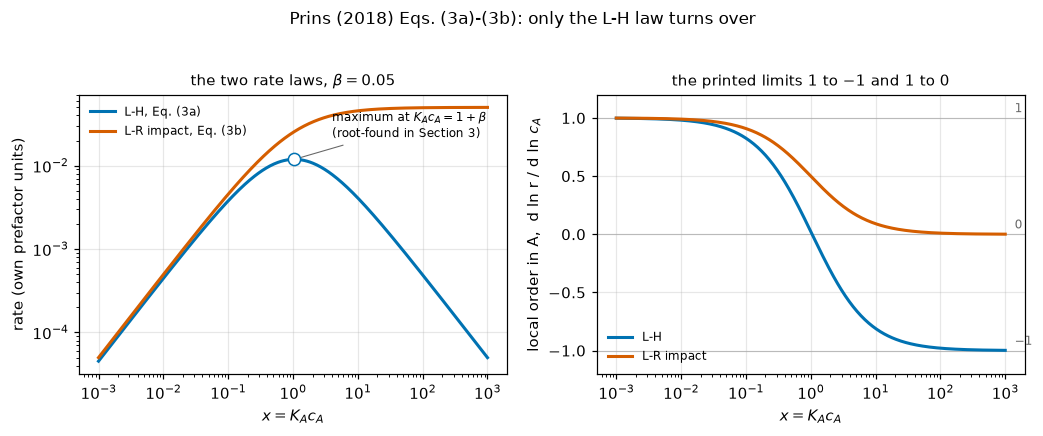

In [7]:
# Figure 1: the two laws and their local orders. L-H is blue, L-R orange on every figure.
xg = np.logspace(-3, 3, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.8))
ax1.loglog(xg, r_lh(xg), color=COL["lh"], lw=2, label="L-H, Eq. (3a)")
ax1.loglog(xg, r_lr(xg), color=COL["lr"], lw=2, label="L-R impact, Eq. (3b)")
xs = 1 + BETA        # the derived maximum, K_A c_A = 1 + beta (symbolic route, Section 1)
ax1.plot([xs], [r_lh(xs)], "o", ms=8, color=COL["lh"], mfc="white", zorder=5)
ax1.annotate("maximum at $K_Ac_A = 1+\\beta$\n(root-found in Section 3)",
             xy=(xs, r_lh(xs)), xytext=(4, 2.2e-2), fontsize=8,
             arrowprops=dict(arrowstyle="-", lw=0.7, color="0.4"))
ax1.set_xlabel("$x = K_A c_A$"); ax1.set_ylabel("rate (own prefactor units)")
ax1.set_title("the two rate laws, $\\beta = %.2f$" % BETA, fontsize=10)
ax1.legend(frameon=False, fontsize=8)
ax2.semilogx(xg, slope(r_lh, xg), color=COL["lh"], lw=2, label="L-H")
ax2.semilogx(xg, slope(r_lr, xg), color=COL["lr"], lw=2, label="L-R impact")
ax2.set_ylim(-1.2, 1.2)
for y, lab in ((1, "1"), (0, "0"), (-1, "−1")):
    ax2.axhline(y, color="0.75", lw=0.7, zorder=0)
    ax2.text(1.4e3, y + 0.05, lab, fontsize=8, color="0.4")
ax2.set_xlabel("$x = K_A c_A$"); ax2.set_ylabel("local order in A,  d ln r / d ln $c_A$")
ax2.set_title("the printed limits 1 to −1 and 1 to 0", fontsize=10)
ax2.legend(frameon=False, fontsize=8)
fig.suptitle("Prins (2018) Eqs. (3a)-(3b): only the L-H law turns over", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

### 3. The maximum of the L-H rate, and the printed condition that cannot be right

The paper prints (p. 719, quoted verbatim in *The published model*): "The rate
of the L-H reaction should even reach a maximum for c$_A$ = K$_A$." The
maximum is real, it is the L-H law's signature and the reason the two laws are
distinguishable at all, but the printed condition equates a concentration to an
inverse concentration. Three computations pin this down:

1. **the closed form** from the paper's own Eq. (3a), $K_Ac_A^* = 1 + K_Bc_B$
   (sympy, Section 1);
2. **the numeric root** of $\mathrm{d}\ln r/\mathrm{d}\ln x = 0$ on the *NumPy-coded*
   law, sharing no algebra with the closed form: `find_roots` on $x \in [10^{-3}, 10^{3}]$,
   exactly one root required, and pymrm's `newton` on a `NumJac((1, 1))` Jacobian as the
   cross-check route, its `success` checked;
3. **the unit test the printed condition fails**: a physical condition must not
   care whether concentration is in mol/L or mol/m³. The derived condition gives the
   same physical $c_A^*$ in both unit systems (ratio 1); the printed one moves it by
   the square of the unit factor.

In [8]:
BETA_M = 0.3         # K_B c_B where the maximum is located
KA_L = 2.0           # L/mol: an arbitrary working K_A for the unit test; the test varies the units
LAM = 1000.0         # mol/L to mol/m3: c' = LAM c, K' = K / LAM


def maxloc(beta_law=BETA_M, beta_closed=BETA_M, beta_newton=None, condition="derived"):
    """Where d ln r / d ln x = 0 on the NumPy-coded law, by ``find_roots`` on the physical range
    (exactly one root) and by ``newton``; the closed form is that of the symbolic route
    (``condition="printed"`` instead takes the printed c_A = K_A, that is K_A c_A = K_A**2).
    ``beta_newton`` runs newton on the law at another beta (a mis-wired cross-check)."""
    g = lambda xv: slope(lambda u: r_lh(u, b=beta_law), xv)
    x_root = one_root(g, 1e-3, 1e3, n=64, log=True, xtol=1e-13)
    gn = g if beta_newton is None else (lambda xv: slope(lambda u: r_lh(u, b=beta_newton), xv))
    jac = NumJac((1, 1))
    res = newton(lambda zz: jac(lambda q: np.array([[gn(float(np.exp(q[0, 0])))]]), zz),
                 np.array([[0.0]]), tol=1e-8, maxfev=200, stagnation=True)   # unknown is ln x
    if not res.success:
        raise RuntimeError(f"newton did not converge: {res.message}")
    x_newton = float(np.exp(res.x[0, 0]))
    x_closed = 1.0 + beta_closed if condition == "derived" else KA_L ** 2
    return {"maxloc_xstar_beta03": x_root,
            "maxloc_closed_minus_root_rel": abs(x_root / x_closed - 1.0),
            "maxloc_newton_minus_root_rel": abs(x_newton / x_root - 1.0)}


def unit_ratio(condition="derived"):
    """Physical c_A* in mol/m3 from the condition solved in mol/L units over the same solved
    directly in m3 units."""
    if condition == "derived":      # K_A c_A = 1 + beta
        return (1 + BETA_M) / KA_L * LAM / ((1 + BETA_M) / (KA_L / LAM))
    return KA_L * LAM / (KA_L / LAM)  # printed c_A = K_A, read literally in each system


mx = maxloc()
claims.value("maxloc_xstar_beta03", mx["maxloc_xstar_beta03"], rtol=1e-3)
claims.bound("maxloc_closed_minus_root_rel", mx["maxloc_closed_minus_root_rel"], max=1e-8,
             basis="tolerance")
claims.bound("maxloc_newton_minus_root_rel", mx["maxloc_newton_minus_root_rel"], max=1e-6,
             basis="tolerance")
claims.bound("derived_maxcond_unit_ratio", unit_ratio("derived"), min=1 - 1e-12, max=1 + 1e-12,
             basis="identity")
claims.value("printed_maxcond_unit_ratio", unit_ratio("printed"), rtol=1e-6)

brk_all("rate law coded at beta = 0.35, closed form at 0.3",
        {n: v for n, v in maxloc(beta_law=0.35).items() if n in ("maxloc_xstar_beta03", "maxloc_closed_minus_root_rel")})
brk("adopt the printed condition c_A = K_A (working K_A in mol/L)", "maxloc_closed_minus_root_rel",
    maxloc(condition="printed")["maxloc_closed_minus_root_rel"])
BETA_BAD = 0.35
brk(f"newton run on the law at beta = {BETA_BAD}", "maxloc_newton_minus_root_rel",
    maxloc(beta_newton=BETA_BAD)["maxloc_newton_minus_root_rel"])
brk("the unit rescale applied to the printed condition", "derived_maxcond_unit_ratio", unit_ratio("printed"))
brk("the unit rescale applied to the derived condition", "printed_maxcond_unit_ratio", unit_ratio("derived"))

say("""Closed form: $K_Ac_A^* = 1+\\beta = @@xc@@$. Numeric route on the NumPy law, `find_roots` with
exactly one root on the physical range: $K_Ac_A^* = @@xr@@$, within @@g1@@ (relative) of the closed
form, which is the independent second computation of this headline. pymrm's `newton` on
`NumJac((1, 1))` agrees with the root to @@g2@@, a root-finder cross-check only, since it shares the
objective. Unit test: rescaling mol/L to mol/m³ moves the physical $c_A^*$ implied by the printed
condition by a factor **@@pr@@** $= \\lambda^2$, while the derived condition's ratio is **@@dr@@**.
The printed "c$_A$ = K$_A$" is reported as a defect and left as printed; the reduced-form reading
$K_Ac_A = 1$ is an inference, labelled as such.""",
    xc=1 + BETA_M, xr=f"{claims['maxloc_xstar_beta03']:.10f}",
    g1=f"{claims['maxloc_closed_minus_root_rel']:.0e}", g2=f"{claims['maxloc_newton_minus_root_rel']:.0e}",
    pr=f"{claims['printed_maxcond_unit_ratio']:.3g}", dr=f"{claims['derived_maxcond_unit_ratio']:.3g}")

Closed form: $K_Ac_A^* = 1+\beta = 1.3$. Numeric route on the NumPy law, `find_roots` with
exactly one root on the physical range: $K_Ac_A^* = 1.3000000008$, within 6e-10 (relative) of the closed
form, which is the independent second computation of this headline. pymrm's `newton` on
`NumJac((1, 1))` agrees with the root to 6e-10, a root-finder cross-check only, since it shares the
objective. Unit test: rescaling mol/L to mol/m³ moves the physical $c_A^*$ implied by the printed
condition by a factor **1e+06** $= \lambda^2$, while the derived condition's ratio is **1**.
The printed "c$_A$ = K$_A$" is reported as a defect and left as printed; the reduced-form reading
$K_Ac_A = 1$ is an inference, labelled as such.

### 4. The (3c)-(3b) degeneracy, sharpened

The paper warns that with $K_Bc_B \ll 1$ Eq. (3c) "becomes equal to" Eq. (3b)
"and it looks as if an L-R reaction takes place". Two sharpenings, both
following from the algebra:

- **Along a $c_A$-sweep at fixed $c_B$ the degeneracy is exact at *any*
  $\beta$, not only for $\beta \ll 1$:** $r_{3c}/r_{3b} = 1/(1+\beta)$ in the
  normalised units, independent of $c_A$, and a fitted rate constant absorbs any
  constant. A kinetic study that varies only the chemisorbing species'
  concentration **cannot distinguish non-competing dual-site L-H from the impact
  law, no matter how wide the range**. (Strictly, "becomes equal" also needs the
  rate constant reinterpreted, $k_{3b} = k_{3c}K_B$, the paper's operational
  meaning, since $k$ is fitted.)
- **The discriminating direction is $c_B$**, where the two laws' orders differ by
  $\beta/(1+\beta)$: first order exactly (3b) against $1-\beta/(1+\beta)$ (3c).

In [9]:
BETA_D = 0.3


def degeneracy(beta=BETA_D, beta_factor=None, beta_closed=None):
    """Sup over twelve decades of c_A of |r_3c (1 + beta_factor) / r_3b - 1| (zero by algebra at
    beta_factor = beta), and the order-in-B gap of Eq. (3c) against beta/(1 + beta)."""
    xg2 = np.logspace(-6, 6, 2001)
    r3c = xg2 * beta / ((1 + xg2) * (1 + beta))
    r3b = xg2 * beta / (1 + xg2)
    bf = beta if beta_factor is None else beta_factor
    gap = 1.0 - slope(lambda bv: bv / ((1 + 1.0) * (1 + bv)), beta)
    bc = beta if beta_closed is None else beta_closed
    return {"deg3c3b_sup_dev_fixed_cB": float(np.max(np.abs(r3c / r3b * (1 + bf) - 1.0))),
            "deg3c3b_orderB_gap_beta03": gap,
            "deg3c3b_gap_vs_closed_form": abs(gap - bc / (1 + bc))}


dg = degeneracy()
claims.bound("deg3c3b_sup_dev_fixed_cB", dg["deg3c3b_sup_dev_fixed_cB"], max=1e-12, basis="identity")
claims.value("deg3c3b_orderB_gap_beta03", dg["deg3c3b_orderB_gap_beta03"], rtol=1e-3)
claims.bound("deg3c3b_gap_vs_closed_form", dg["deg3c3b_gap_vs_closed_form"], max=1e-8, basis="tolerance")
brk("the proportionality factor taken as 1 + 1.3 beta", "deg3c3b_sup_dev_fixed_cB",
    degeneracy(beta_factor=1.3 * BETA_D)["deg3c3b_sup_dev_fixed_cB"])
brk("beta -> 0", "deg3c3b_orderB_gap_beta03", degeneracy(beta=1e-9)["deg3c3b_orderB_gap_beta03"])
brk("closed form evaluated at beta = 0.35, law at 0.3", "deg3c3b_gap_vs_closed_form",
    degeneracy(beta_closed=0.35)["deg3c3b_gap_vs_closed_form"])

say("""Over twelve decades of $c_A$ the deviation of $r_{3c}(1+\\beta)$ from $r_{3b}$ is below @@b@@ (here
@@s@@): an identity, which can catch nothing but a slip in this cell. Its companion that *can*
fail: the order-in-B gap at $\\beta = @@beta@@$, measured **@@g@@** against the analytic
$\\beta/(1+\\beta)$ to within @@gg@@, the size of the only kinetic signal separating (3c) from the
impact law.""",
    b="1e-12", s=f"{claims['deg3c3b_sup_dev_fixed_cB']:.0e}", beta=BETA_D,
    g=f"{claims['deg3c3b_orderB_gap_beta03']:.6f}", gg=f"{claims['deg3c3b_gap_vs_closed_form']:.0e}")

Over twelve decades of $c_A$ the deviation of $r_{3c}(1+\beta)$ from $r_{3b}$ is below 1e-12 (here
2e-16): an identity, which can catch nothing but a slip in this cell. Its companion that *can*
fail: the order-in-B gap at $\beta = 0.3$, measured **0.230769** against the analytic
$\beta/(1+\beta)$ to within 7e-11, the size of the only kinetic signal separating (3c) from the
impact law.

### 5. How wide a concentration range before the laws separate? Root-found

The paper (p. 719): "If one could vary the concentration of A over a wide
range, it would be possible to distinguish between the two mechanisms.
Unfortunately, concentrations can often only be varied in a limited range in
the liquid phase. In such a case, the R² factor for one model may be better
than for the other, but the question if one of the two models can be rejected
remains unanswered."

This section turns that paragraph into a number. Take **noiseless** rates from
the L-H law (reduced 3a) on a log-window of $x$ of total span $w$ centred on
the L-H maximum $x=1$ (the most discriminating placement: the L-R law is
monotone and can never turn over), and **fit the impact law to them** with
$\ln k'$ and $K'$ free, on a fixed 401-point log grid of the window. The
misfit $\mathrm{dev}(w)$ is the **mean absolute log-deviation** on the window
(about the mean relative deviation, the same scale as the 1947 fit's average
deviation). The data are noiseless, so $\mathrm{dev}$ is a model discrepancy, not
a statistical estimate and carries no standard error; the fit has two
parameters on the grid's points, so its degrees of freedom are two fewer than
the grid. The identifiability threshold $w^*$ solves
$\mathrm{dev}(w^*) = \text{tolerance}$ on $w \in [1.05, 5\times10^4]$ with
`find_roots`, exactly one root required, never read off a sweep.

The objective is a mean of absolute values, which has no analytic derivative at
its minimum, so the minimiser is a **scan plus a refinement, and the scan is
stated**. $\mathrm{dev}(w)$ is computed by **two routes sharing only the metric's
definition** (grid, norm, noiseless generator): (A) a joint scan of
$(\ln k', \ln K')$ on a $25\times25$ grid, then Nelder-Mead from the best scan
point and from three fixed starts, keeping the lowest; (B) the exact
median-profile of $\ln k'$ (for the mean absolute norm the optimal intercept is
the residual median) followed by a scan of $\ln K'$ on 121 points over
$[-15, 15]$ and a bounded Brent refinement inside the bracket of the best scan
point. Different search space, different optimizer family, no shared iteration.
The tolerances are the book's own average deviation, recomputed from Table C's
printed percentages, a 5 % level, and `C1.1`'s published rate-space scatter.

In [10]:
NW = 401                     # the metric's definition grid (refined below)
W_LO, W_HI = 1.05, 5e4       # physical range of the window span w (w > 1; the upper end is far
                             # past the largest threshold, which the scan must find inside it)
TOL_BOOK = float(TC.pct_delta_printed.abs().mean()) / 100   # the book's average deviation, Table C
TOL_5 = 0.05                                                # a 5 % precision, chosen
TOL_RATE = C11["rate_space_scatter_pct_200C"] / 100         # C1.1's published rate-space scatter


def _window(w, x0, n):
    t = np.linspace(-0.5, 0.5, n) * np.log(w)
    xv = x0 * np.exp(t)
    return xv, np.log(xv) - 2.0 * np.log1p(xv)          # ln r of reduced Eq. (3a)


def window_misfit(w, x0=1.0, n=NW, route="A", norm="mean"):
    """Best impact-law misfit to noiseless L-H rates on the window of span ``w`` centred at
    ``x0``, by route A (2-D scan then Nelder-Mead) or route B (median profile, scan of ln K',
    bounded refine). ``norm="max"`` is the worst-case misfit (route A only)."""
    xv, lr = _window(w, x0, n)
    lx = np.log(xv)
    if route == "A":
        red = np.max if norm == "max" else np.mean
        obj = lambda p: red(np.abs(p[0] + lx - np.log1p(np.exp(p[1]) * xv) - lr))
        LK, LQ = np.meshgrid(np.linspace(-3, 3, 25), np.linspace(-6, 6, 25))
        scan = red(np.abs(LK[..., None] + lx - np.log1p(np.exp(LQ)[..., None] * xv) - lr), axis=-1)
        i = np.unravel_index(np.argmin(scan), scan.shape)
        starts = ([LK[i], LQ[i]], [0.0, 0.0], [-2.0, 2.0], [2.0, -2.0])
        return min(minimize(obj, s0, method="Nelder-Mead",
                            options=dict(xatol=1e-11, fatol=1e-13, maxiter=40000)).fun
                   for s0 in starts)
    if norm != "mean":
        raise ValueError("route B is the exact profile of the mean absolute norm only")

    def g(lnq):
        e = lr - (lx - np.log1p(np.exp(lnq) * xv))
        return np.mean(np.abs(e - np.median(e)))         # exact profile of ln k'
    lq = np.linspace(-15, 15, 121)
    vals = np.array([g(q) for q in lq])
    i = int(np.argmin(vals))
    if i in (0, len(lq) - 1):
        raise ValueError(f"the best ln K' is at or beyond the end of [-15, 15] for w = {w:.4g}")
    return minimize_scalar(g, bounds=(lq[i - 1], lq[i + 1]), method="bounded",
                           options=dict(xatol=1e-12)).fun


def wstar(tol, route="A", x0=1.0, n=NW, norm="mean"):
    """The window span at which the misfit equals ``tol``: exactly one root on [W_LO, W_HI]."""
    return one_root(lambda w: window_misfit(w, x0, n, route, norm) - tol, W_LO, W_HI,
                    n=24, log=True, xtol=1e-8)


wstar_A = wstar(TOL_BOOK)
wstar_B = wstar(TOL_BOOK, route="B")
wstar_B_fine = wstar(TOL_BOOK, route="B", n=1601)
wstar_all = {"wstar_tol844": wstar_A, "wstar_tol5": wstar(TOL_5), "wstar_tol169": wstar(TOL_RATE)}
print({k: round(v, 4) for k, v in wstar_all.items()}, "route B:", round(wstar_B, 4))


def smallw_const(x0=1.0):
    return window_misfit(1.2, x0, route="B") / np.log(1.2) ** 2


for name, v in wstar_all.items():
    claims.value(name, v, rtol=1e-3)
claims.bound("wstar_tol844_two_routes_rel", abs(wstar_A / wstar_B - 1.0), max=1e-6, basis="tolerance")
claims.bound("wstar_tol844_grid_refined_rel", abs(wstar_B_fine / wstar_B - 1.0), max=2e-2,
             basis="chosen", note="about four times the measured effect of 401 to 1601 points; "
                                  "the break row uses a 21-point definition grid")
claims.value("smallw_quad_const", smallw_const(), rtol=1e-3)
dev_center001 = window_misfit(wstar_A, x0=0.01)
claims.value("dev_at_wstar_center001", dev_center001, rtol=1e-3)

brk_helper("window centred at x0 = 0.01, where both laws are first order", lambda: {
    "wstar_tol844": wstar(TOL_BOOK, x0=0.01)}, ["wstar_tol844"])
brk_helper("worst-case (minimax) norm instead of the mean", lambda: {
    "wstar_tol844": wstar(TOL_BOOK, norm="max"), "wstar_tol5": wstar(TOL_5, norm="max"),
    "wstar_tol169": wstar(TOL_RATE, norm="max")}, list(wstar_all))
brk("route B window centred at x0 = 0.5", "wstar_tol844_two_routes_rel",
    abs(wstar_A / wstar(TOL_BOOK, route="B", x0=0.5) - 1.0))
brk("definition grid of 21 points", "wstar_tol844_grid_refined_rel",
    abs(wstar_B_fine / wstar(TOL_BOOK, route="B", n=21) - 1.0))
brk("small window centred at x0 = 0.01", "smallw_quad_const", smallw_const(x0=0.01))
brk("misfit read at the window centred at x0 = 0.02", "dev_at_wstar_center001",
    window_misfit(wstar_A, x0=0.02))

say("""**$w^* = @@w@@$** at the tolerance of the book's own average deviation (@@tb@@ %, recomputed
from Table C's printed percentages). Routes A and B agree to @@g1@@; moving route B's definition grid
from 401 to 1601 points moves it by @@g2@@. The chemisorbing species' concentration must span a
factor of about **@@wr@@, just over a decade, centred on the L-H maximum** before the best impact-law
fit misses noiseless L-H rates by more than that deviation. At 5 %: $w^* = @@w5@@$. At `C1.1`'s
rate-space scatter (@@ts@@ %, from its claims): $w^* = @@w169@@$. Small windows obey
$\\mathrm{dev} \\approx C(\\ln w)^2$ with measured $C = @@c@@$ (a measured constant, not a derived
one). Centre the window where both laws are first order and the misfit at $w^*$ falls to @@d@@
against the tolerance of @@tb2@@, a factor of @@fac@@ lower (the break table shows that no span up to
$@@whi@@$ then reaches the tolerance). **Width buys nothing without curvature**, which is the
quantitative content of the paper's "limited range" warning.""",
    w=f"{wstar_A:.2f}", tb=f"{100 * TOL_BOOK:.2f}", tb2=f"{TOL_BOOK:.4f}",
    g1=f"{claims['wstar_tol844_two_routes_rel']:.0e}", g2=f"{claims['wstar_tol844_grid_refined_rel']:.1e}",
    wr=f"{round(wstar_A)}", w5=f"{claims['wstar_tol5']:.2f}", ts=f"{100 * TOL_RATE:.2f}",
    w169=f"{claims['wstar_tol169']:.1f}", c=f"{claims['smallw_quad_const']:.4f}",
    d=f"{dev_center001:.1e}", fac=f"{TOL_BOOK / dev_center001:.0f}", whi=f"{W_HI:.0f}")

{'wstar_tol844': 11.7522, 'wstar_tol5': 6.3663, 'wstar_tol169': 39.768} route B: 11.7522


**$w^* = 11.75$** at the tolerance of the book's own average deviation (8.44 %, recomputed
from Table C's printed percentages). Routes A and B agree to 3e-11; moving route B's definition grid
from 401 to 1601 points moves it by 4.6e-03. The chemisorbing species' concentration must span a
factor of about **12, just over a decade, centred on the L-H maximum** before the best impact-law
fit misses noiseless L-H rates by more than that deviation. At 5 %: $w^* = 6.37$. At `C1.1`'s
rate-space scatter (16.86 %, from its claims): $w^* = 39.8$. Small windows obey
$\mathrm{dev} \approx C(\ln w)^2$ with measured $C = 0.0157$ (a measured constant, not a derived
one). Centre the window where both laws are first order and the misfit at $w^*$ falls to 5.3e-05
against the tolerance of 0.0844, a factor of 1589 lower (the break table shows that no span up to
$50000$ then reaches the tolerance). **Width buys nothing without curvature**, which is the
quantitative content of the paper's "limited range" warning.

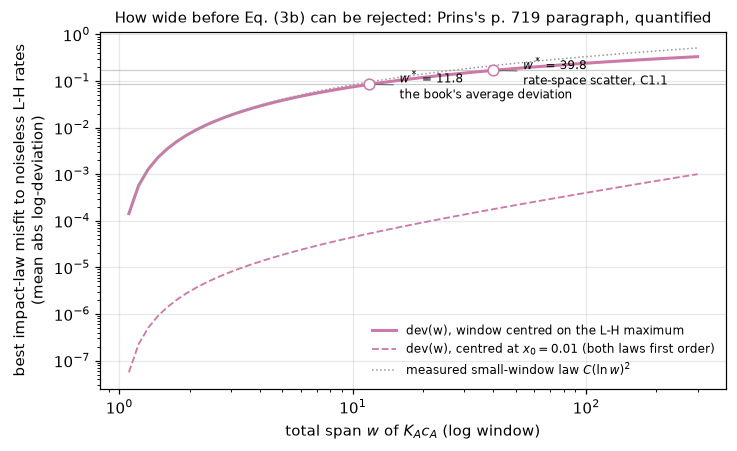

In [11]:
# Figure 2: the identifiability window (route B, which is fast; route A is the check).
wg = np.logspace(np.log10(1.1), np.log10(300), 60)
dv = np.array([window_misfit(w, route="B") for w in wg])
dv001 = np.array([window_misfit(w, x0=0.01, route="B") for w in wg])
fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.loglog(wg, dv, color=COL["win"], lw=2, label="dev(w), window centred on the L-H maximum")
ax.loglog(wg, dv001, color=COL["win"], lw=1.2, ls="--",
          label="dev(w), centred at $x_0=0.01$ (both laws first order)")
ax.loglog(wg, claims["smallw_quad_const"] * np.log(wg) ** 2, color="0.6", lw=1, ls=":",
          label="measured small-window law $C(\\ln w)^2$")
for tol, lab, ws in ((TOL_BOOK, "the book's average deviation", claims["wstar_tol844"]),
                     (TOL_RATE, "rate-space scatter, C1.1", claims["wstar_tol169"])):
    ax.axhline(tol, color="0.8", lw=0.8, zorder=0)
    ax.plot([ws], [tol], "o", ms=7, color=COL["win"], mfc="white", zorder=5)
    ax.annotate(f"$w^*$ = {ws:.1f}\n{lab}", xy=(ws, tol), xytext=(ws * 1.35, tol * 0.5),
                fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.7, color="0.4"))
ax.set_xlabel("total span $w$ of $K_Ac_A$ (log window)")
ax.set_ylabel("best impact-law misfit to noiseless L-H rates\n(mean abs log-deviation)")
ax.set_title("How wide before Eq. (3b) can be rejected: Prins's p. 719 paragraph, quantified",
             fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

### 6. The impact law on the founding LHHW dataset: a numerical experiment

Everything above is dimensionless. This section instantiates both laws with
**real fitted constants imported from `C1.1`**, the codimer hydrogenation of
Hougen and Watson (1947), the dataset on which LHHW estimation was founded,
and asks the question this page's two sources jointly pose: **could the
founding dataset have rejected the impact mechanism on fit quality?**

The book's candidate mechanisms already *include* impact forms: its groups
III-V are gas-phase reactant against adsorbed partner, and its mechanism
**(o)**, $r = k'K_Up_Up_H/(1+K_Up_U+K_Sp_S)$, is **exactly Prins's Eq. (3b)**
instantiated for chemisorbed codimer (with the product's adsorption term
retained) and colliding H₂, hydrogen in the numerator only. The book rejected
(o) by its **sign test** (its printed verdict in Table D: `f0;apos`, a term that
should be absent is fitted nonzero), not by fit quality. Two cautions from `C1.1`,
honoured here: the printed 200 °C rows of the impact mechanisms sit in the
**corrupted-worksheet family**, so their printed constants are never used
(everything is refitted from Table A); and `C1.1` showed the "a should be
positive" ground itself partly rests on the corrupted sum, while the
acceptance set {d, h} survives.

**All of this is fit data and numerical experiment, no validation.** What is fitted
to what: each impact form is fitted to a set of target rates by least squares on
the **relative** residuals, with log-parameterised positive constants, from three
fixed starts, by Levenberg-Marquardt (`scipy.optimize.least_squares`). The targets are
either **noiseless rates generated from mechanism (d)** at the printed compositions
(the power study), or the **measured rates** of the printed runs. A second optimizer
family, a bounded trust-region fit on the positive parameters, is the cross-check.
The converted constants are `C1.1`'s: $K_U = b/a$, $K_S = c/a$, $K_H = f/a$, and the
lumped prefactor $1/a^2$. A defect is entered by inverting one conversion ($a/b$ for
$b/a$) or by scaling the hydrogen term of the generator.

In [12]:
H, U, S, robs = (blk[kk].to_numpy() for kk in ("pH_atm", "pU_atm", "pS_atm", "r_lbmol_per_lb_hr"))
d_row = DEF[(DEF.mechanism == "d") & (DEF.temp_C == T_DESIGN)].iloc[0]       # the CLEAN row (C1.1)
o_row = DEF[(DEF.mechanism == "o") & (DEF.temp_C == T_DESIGN)].iloc[0]
print("printed 200 C verdict for the impact mechanism (o):", repr(o_row.verdict),
      "(its printed constants are in the corrupted family, NOT used; refitted from Table A below)")


def codimer(inverted=()):
    """Mechanism (d)'s constants at 200 C in C1.1's conversion. Each name in ``inverted`` takes
    a/x in place of x/a for that constant (the injected defect)."""
    a, b, c, f = (float(d_row[kk]) for kk in ("a", "b", "c", "f"))
    return dict(KU=(a / b if "KU" in inverted else b / a), KS=(a / c if "KS" in inverted else c / a),
                KH=(a / f if "KH" in inverted else f / a), kap=1.0 / a ** 2, a=a)


FORMS = {   # number of parameters, rate as a function of (p, pH, pU, pS)
    "o": (3, lambda p, Hv, Uv, Sv: p[0] * Hv * Uv / (1 + p[1] * Uv + p[2] * Sv)),            # Eq. (3b) = mechanism (o)
    "p": (2, lambda p, Hv, Uv, Sv: p[0] * Hv * Uv / (1 + p[1] * Uv)),                        # (3b) without the product term
    "oH": (4, lambda p, Hv, Uv, Sv: p[0] * Hv * Uv / (1 + p[1] * Uv + p[2] * Sv + p[3] * Hv)),  # first power, H term allowed
    "d": (4, lambda p, Hv, Uv, Sv: p[0] * Hv * Uv / (1 + p[1] * Hv + p[2] * Uv + p[3] * Sv) ** 2)}


def fit_form(form, Hv, Uv, Sv, target):
    """Relative-residual least squares of ``FORMS[form]`` to ``target``; returns the parameters and
    the per-run absolute relative residuals in per cent."""
    npar, fun = FORMS[form]
    res = lambda lp: (fun(np.exp(lp), Hv, Uv, Sv) - target) / target
    best = min((least_squares(res, x0, method="lm", max_nfev=40000)
                for x0 in (np.zeros(npar), np.full(npar, -1.0), np.full(npar, 1.0))),
               key=lambda s: s.cost)
    return np.exp(best.x), 100 * np.abs(best.fun)


def rate_d(cd, Hv, Uv, Sv, KH_scale=1.0):
    """The noiseless mechanism-(d) rate: the generator of the power study."""
    return cd["kap"] * Hv * Uv / (1 + KH_scale * cd["KH"] * Hv + cd["KU"] * Uv + cd["KS"] * Sv) ** 2


def codimer_results(inverted=(), KH_scale=1.0, exclude=("25a",), relative=True, closed_pS=None, newton_pS=None):
    """Every Section 6 claim that depends on the converted constants and the generator.
    ``relative=False`` fits the cross-check route to absolute instead of relative residuals;
    ``closed_pS`` evaluates the closed form at another p_S, ``newton_pS`` runs newton at another p_S."""
    cd = codimer(inverted)
    out = {"codimer_KU_per_atm": cd["KU"], "codimer_KH_per_atm": cd["KH"], "codimer_KS_per_atm": cd["KS"]}
    # reconciliation with the book's own printed Table C: R_calc = a (1 + K_H pH + K_U pU + K_S pS)
    R = cd["a"] * (1 + cd["KH"] * H + cd["KU"] * U + cd["KS"] * S)
    printed = TC.R_calc_printed.loc[blk.run].to_numpy()
    unit = np.array([10.0 ** -len(TCs.R_calc_printed[r].split(".")[1]) for r in blk.run])
    gap = np.abs(R - printed)
    keep_ = ~blk.run.isin(exclude).to_numpy()
    out["codimer_Rcalc_gaps_in_units"] = gap / unit
    out["codimer_Rcalc_rows_within_one_unit"] = int(np.sum(gap / unit < 1.0))
    out["codimer_Rcalc_worst_gap_units_ex25a"] = float((gap / unit)[keep_].max())
    out["codimer_25a_abs_gap"] = float(gap[(blk.run == "25a").to_numpy()][0])
    out["codimer_25a_gap_vs_C11"] = abs(out["codimer_25a_abs_gap"] - C11["tableC_25a_printed_minus_consistent"])
    # rate-space scatter of the fitted (d) law against the measured rates
    scatter = 100 * np.abs(rate_d(cd, H, U, S) / robs - 1).mean()
    out["codimer_d_scatter_pct"] = scatter
    out["codimer_scatter_vs_C11"] = abs(scatter / C11["rate_space_scatter_pct_200C"] - 1.0)
    # the power study: noiseless (d) rates, refitted by the impact forms
    r_exact = rate_d(cd, H, U, S, KH_scale)
    po, pct_o = fit_form("o", H, U, S, r_exact)
    out["lr_o_on_exact_d_mean_pct"], out["lr_o_on_exact_d_max_pct"] = pct_o.mean(), pct_o.max()
    resB = lambda p: (FORMS["o"][1](p, H, U, S) - r_exact) / (r_exact if relative else 1.0)
    sB = least_squares(resB, np.array([0.1, 1.0, 1.0]), bounds=(1e-12, np.inf), method="trf",
                       xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=60000)
    out["lr_o_fit_two_routes_rel"] = abs(pct_o.mean() / (100 * np.abs((FORMS["o"][1](sB.x, H, U, S) - r_exact) / r_exact).mean()) - 1.0)
    # the mean |relative residual| minimised directly: Nelder-Mead from the least-squares optimum and three fixed starts
    mean_abs = lambda lp: np.mean(np.abs((FORMS["o"][1](np.exp(lp), H, U, S) - r_exact) / r_exact))
    out["lr_o_direct_mean_pct"] = 100 * min(
        minimize(mean_abs, x0, method="Nelder-Mead", options=dict(xatol=1e-10, fatol=1e-13, maxiter=40000)).fun
        for x0 in (np.log(po), np.zeros(3), np.full(3, -1.0), np.full(3, 1.0)))
    out["lr_p_on_exact_d_mean_pct"] = fit_form("p", H, U, S, r_exact)[1].mean()
    out["lr_oKH_on_exact_d_mean_pct"] = fit_form("oH", H, U, S, r_exact)[1].mean()
    Hc = np.full_like(H, H.mean())          # the design's hydrogen span collapsed to its mean
    out["lr_o_collapsedpH_mean_pct"] = fit_form("o", Hc, U, S, rate_d(cd, Hc, U, S, KH_scale))[1].mean()
    # the L-H maximum in p_U at p_H = p_S = 0.5 atm: find_roots on the physical range, newton, closed form
    pH0, pS0 = 0.5, 0.5
    gU = lambda pU: slope(lambda u: rate_d(cd, pH0, u, pS0), pU)
    gUn = lambda pU: slope(lambda u: rate_d(cd, pH0, u, pS0 if newton_pS is None else newton_pS), pU)
    root = one_root(gU, 0.02, 40.0, n=64, log=True, xtol=1e-13)
    jac = NumJac((1, 1))
    nres = newton(lambda zz: jac(lambda q: np.array([[gUn(float(np.exp(q[0, 0])))]]), zz),
                  np.array([[0.5]]), tol=1e-8, maxfev=200, stagnation=True)      # unknown is ln p_U
    if not nres.success:
        raise RuntimeError(f"newton did not converge: {nres.message}")
    closed = (1 + cd["KH"] * pH0 + cd["KS"] * (pS0 if closed_pS is None else closed_pS)) / cd["KU"]
    out["codimer_pUstar_atm"] = root
    out["codimer_pUstar_vs_closed_rel"] = abs(root / closed - 1.0)
    out["codimer_pUstar_newton_rel"] = abs(float(np.exp(nres.x[0, 0])) / root - 1.0)
    out["pUstar_margin_to_design_ends"] = min(root - U.min(), U.max() - root) / root
    out["pUstar_inside_design"] = bool(U.min() < root < U.max())
    return out


def tablec_mean_pct(slip=None):
    """The mean absolute deviation of Table C's printed percentages, and its distance from the
    published recomputation of `C1.1`; ``slip`` multiplies one printed percentage."""
    pct = TC.pct_delta_printed.abs().copy()
    for run, f in (slip or {}).items():
        pct[run] *= f
    m = float(pct.mean())
    return {"codimer_tableC_avg_abs_pct": m, "codimer_tableC_vs_C11_recompute": abs(m - C11["tableC_avg_abs_pct"])}


def measured_fits(rates, se_power=0.5):
    """Mechanism (d) (4 parameters) and (o) (3 parameters) fitted to the ``rates`` of the runs;
    the paired per-run difference of their residuals and its standard error sd / n**se_power
    (the standard error of a mean is sd / sqrt(n))."""
    _, pd_ = fit_form("d", H, U, S, rates)
    _, po_ = fit_form("o", H, U, S, rates)
    diff = po_ - pd_
    return {"lh_d_measured_mean_pct": pd_.mean(), "lr_o_measured_mean_pct": po_.mean(),
            "lr_gap_measured_pct_points": diff.mean(),
            "lr_gap_measured_se_pts": diff.std(ddof=1) / len(diff) ** se_power,
            "lr_gap_measured_over_se": diff.mean() / (diff.std(ddof=1) / len(diff) ** se_power)}


def pH_span(temp_C):
    """Ratio of the largest to the smallest hydrogen pressure of the runs at one temperature."""
    h = A[A.temp_C == temp_C].pH_atm
    return float(h.max() / h.min())


CD = codimer_results()
for name in ("codimer_KU_per_atm", "codimer_KH_per_atm", "codimer_KS_per_atm", "codimer_25a_abs_gap",
             "codimer_Rcalc_worst_gap_units_ex25a", "codimer_d_scatter_pct", "lr_o_on_exact_d_mean_pct",
             "lr_o_on_exact_d_max_pct", "lr_o_direct_mean_pct", "lr_p_on_exact_d_mean_pct", "lr_oKH_on_exact_d_mean_pct",
             "lr_o_collapsedpH_mean_pct", "codimer_pUstar_atm"):
    claims.value(name, CD[name], rtol=1e-3)
claims.count("codimer_Rcalc_rows_within_one_unit", CD["codimer_Rcalc_gaps_in_units"], 1.0, above=False,
             min_margin=0.01)
claims.bound("codimer_25a_gap_vs_C11", CD["codimer_25a_gap_vs_C11"], max=1e-2, basis="chosen",
             note="about twice the measured gap, which is smaller than the worst gap of the other rows")
claims.bound("codimer_scatter_vs_C11", CD["codimer_scatter_vs_C11"], max=2e-3, basis="chosen",
             note="about four times the measured relative gap between the two pages' scatter")
claims.bound("lr_o_fit_two_routes_rel", CD["lr_o_fit_two_routes_rel"], max=1e-4, basis="tolerance")
claims.bound("codimer_pUstar_vs_closed_rel", CD["codimer_pUstar_vs_closed_rel"], max=1e-8, basis="tolerance")
claims.bound("codimer_pUstar_newton_rel", CD["codimer_pUstar_newton_rel"], max=1e-6, basis="tolerance")
claims.exact("pUstar_inside_design", CD["pUstar_inside_design"], margin=CD["pUstar_margin_to_design_ends"],
             min_margin=0.01)
tc = tablec_mean_pct()
claims.value("codimer_tableC_avg_abs_pct", tc["codimer_tableC_avg_abs_pct"], rtol=1e-3)
claims.bound("codimer_tableC_vs_C11_recompute", tc["codimer_tableC_vs_C11_recompute"], max=0.05,
             basis="chosen", note="about three times the measured gap")
claims.value("pH_span_factor", pH_span(T_DESIGN), rtol=1e-3)
MF = measured_fits(robs)
for name in ("lh_d_measured_mean_pct", "lr_o_measured_mean_pct", "lr_gap_measured_pct_points",
             "lr_gap_measured_se_pts"):
    claims.value(name, MF[name], rtol=1e-3)
claims.bound("lr_gap_measured_over_se", MF["lr_gap_measured_over_se"], max=2.0, basis="chosen",
             note="two standard errors, the page's convention for calling a paired difference resolved")


def brk_moved(row, got):
    """Break rows for the claims of ``got`` that the defect enters: a value, count or flag that
    changes (a nan counts), and a bound that the defect breaks. A row is not defined for a claim the
    defect leaves where it was."""
    for n, v in got.items():
        if n not in claims.metrics:
            continue
        x = claims[n]
        if claims.metrics[n]["kind"] == "bound":
            if claims.breaks(row, n, v):
                BREAK.append((row, n, x, v, True))
        elif isinstance(x, (bool, int)):
            if v != x:
                brk(row, n, v)
        elif not (np.isfinite(v) and abs(v - x) <= 1e-9 * abs(x) + 1e-12):
            brk(row, n, v)


for kk in ("KU", "KS", "KH"):
    brk_moved(f"{kk} converted as a/x instead of x/a", codimer_results(inverted=(kk,)))
brk_moved("run 25a included in the worst gap", codimer_results(exclude=()))
SCALE = 0.0
brk_moved(f"generator with K_H scaled by {SCALE}", codimer_results(KH_scale=SCALE))
brk_moved("cross-check route fitted to absolute instead of relative residuals", codimer_results(relative=False))
PS_BAD = 0.4
brk_moved(f"closed form of p_U* evaluated at p_S = {PS_BAD}", codimer_results(closed_pS=PS_BAD))
brk_moved(f"newton on p_U* run at p_S = {PS_BAD}", codimer_results(newton_pS=PS_BAD))
SLIP = {"12ab": 0.1}
brk_moved(f"printed percentage of run 12ab with a decimal slip ({SLIP['12ab']})", tablec_mean_pct(SLIP))
brk("block read at 275 C instead of 200 C", "pH_span_factor", pH_span(275))
rates_slip = robs.copy(); rates_slip[(blk.run == "3c").to_numpy()] *= 10
brk_moved("rate of run 3c mistyped with a factor 10", measured_fits(rates_slip))
brk_moved("standard error taken as sd / n", measured_fits(robs, se_power=1.0))

printed 200 C verdict for the impact mechanism (o): 'f0;apos' (its printed constants are in the corrupted family, NOT used; refitted from Table A below)


In [13]:
cd0 = codimer()
say("""Mechanism (d) at 200 °C from Table D's clean row: $K_U = @@ku@@$, $K_S = @@ks@@$, $K_H = @@kh@@$
atm⁻¹. Reconciliation against the book's own printed Table C (compared run by run, in units of the
last printed digit of each $R_{calc}$): **@@n@@ of the @@nr@@ runs** agree to within one unit (worst
gap **@@w@@** unit), and run 25a is off by
**@@g@@**, reproducing `C1.1`'s finding that 25a's printed value is a digit slip (its claim differs
from this gap by @@gd@@, a bound). The printed per-run percentages give a mean |Δ| of **@@m@@ %** in
transformed $R$-space (@@r@@ runs); `C1.1` recomputes @@c11@@ % from the data. The same fit scatters
**@@sc@@ %** in rate space against `C1.1`'s published @@sc11@@ % (relative gap @@rg@@). That rate-space
scatter is the noise floor every discrimination claim below is judged against.""",
    ku=f"{cd0['KU']:.4f}", ks=f"{cd0['KS']:.4f}", kh=f"{cd0['KH']:.4f}",
    n=claims["codimer_Rcalc_rows_within_one_unit"], nr=claims["runs_at_200C"],
    w=f"{claims['codimer_Rcalc_worst_gap_units_ex25a']:.1f}", g=f"{claims['codimer_25a_abs_gap']:.3f}",
    gd=f"{claims['codimer_25a_gap_vs_C11']:.0e}", m=f"{claims['codimer_tableC_avg_abs_pct']:.2f}",
    r=claims["runs_at_200C"], c11=f"{C11['tableC_avg_abs_pct']:.2f}",
    sc=f"{claims['codimer_d_scatter_pct']:.1f}", sc11=f"{C11['rate_space_scatter_pct_200C']:.2f}",
    rg=f"{claims['codimer_scatter_vs_C11']:.0e}")

say("""**The power study (noiseless mechanism-(d) rates at the printed compositions, refitted by the
impact law).** The impact law misses them by **@@mo@@ % mean (@@mx@@ % worst)** over the design, at the
least-squares-optimal fit (the declared protocol; a second optimizer family agrees to
@@t@@; minimising the mean |Δ| directly, by Nelder-Mead from the least-squares optimum and three fixed
starts, gives the smaller @@dm@@ %), against the @@sc@@ % rate-space scatter. So **on noiseless rates the 1947 design separates Prins's Eq. (3b) from mechanism (d) by fit quality alone**, independently of the sign test the book actually used; on the measured runs it does not (next paragraph). The data are
noiseless, so these are model discrepancies without standard errors.

**Against the measured rates** ($n = @@nn@@$ runs): mechanism (d), four fitted parameters, so
@@dd@@ degrees of freedom, fits to a mean absolute relative residual of @@md@@ %; (o), three parameters
and @@do@@ degrees of freedom, to @@mo2@@ %. The paired per-run difference is **@@gp@@ points with a
standard error of @@se@@** (sd/sqrt(n) of the 12 paired differences; the fits' degrees of freedom are not deducted), so it is @@ratio@@ standard errors: **not resolved at two standard errors**
on these runs. (Compare `C1.1`'s published d-versus-h gap of @@c1@@ points and its gap of @@c2@@ points to
the best rejected mechanism: those are pooled over three temperatures, with paired standard errors combined over the three blocks, so they are not a like-for-like comparison with this single-temperature gap.)

**Why the power study works, and when it would not** (break table): allow hydrogen into the
first-power adsorption group and the misfit falls to @@o4@@ %; collapse the design's hydrogen span
(a factor of @@span@@) to a single value and it falls to @@oc@@ %, both below the noise floor. Dropping
the product term goes the other way, to @@op@@ %. The noiseless misfit exceeds the scatter **only because
hydrogen's partial pressure spans more than a decade, the same "wide range" requirement quantified as
$w^* \\approx @@wr@@$ in Section 5.** A narrower design would have been as blind to the mechanism as
Prins says liquid-phase studies are, and the denominator's *exponent* (1 versus 2) is not what is
identified: the first-power fit with a $K_H$ term still misses by a nonzero @@o4@@ %, consistent with
`C1.1`'s finding that d and h (exponents 2 and 3) cannot be separated either.""",
    mo=f"{claims['lr_o_on_exact_d_mean_pct']:.1f}", mx=f"{claims['lr_o_on_exact_d_max_pct']:.0f}",
    t=f"{claims['lr_o_fit_two_routes_rel']:.0e}", sc=f"{claims['codimer_d_scatter_pct']:.1f}",
    dm=f"{claims['lr_o_direct_mean_pct']:.1f}", nn=claims["runs_at_200C"], dd=claims["runs_at_200C"] - 4, do=claims["runs_at_200C"] - 3,
    md=f"{claims['lh_d_measured_mean_pct']:.1f}", mo2=f"{claims['lr_o_measured_mean_pct']:.1f}",
    gp=f"{claims['lr_gap_measured_pct_points']:.1f}", se=f"{claims['lr_gap_measured_se_pts']:.1f}",
    ratio=f"{claims['lr_gap_measured_over_se']:.1f}",
    c1=f"{C11['discrim_d_vs_h_gap_pct_points']:.1f}", c2=f"{C11['discrim_third_best_gap_pct_points']:.1f}",
    o4=f"{claims['lr_oKH_on_exact_d_mean_pct']:.1f}", span=f"{claims['pH_span_factor']:.0f}",
    oc=f"{claims['lr_o_collapsedpH_mean_pct']:.1f}", op=f"{claims['lr_p_on_exact_d_mean_pct']:.1f}",
    wr=round(claims["wstar_tol844"]))

Mechanism (d) at 200 °C from Table D's clean row: $K_U = 0.5543$, $K_S = 0.3659$, $K_H = 0.4094$
atm⁻¹. Reconciliation against the book's own printed Table C (compared run by run, in units of the
last printed digit of each $R_{calc}$): **11 of the 12 runs** agree to within one unit (worst
gap **0.6** unit), and run 25a is off by
**0.503**, reproducing `C1.1`'s finding that 25a's printed value is a digit slip (its claim differs
from this gap by 3e-03, a bound). The printed per-run percentages give a mean |Δ| of **8.44 %** in
transformed $R$-space (12 runs); `C1.1` recomputes 8.42 % from the data. The same fit scatters
**16.8 %** in rate space against `C1.1`'s published 16.86 % (relative gap 5e-04). That rate-space
scatter is the noise floor every discrimination claim below is judged against.

**The power study (noiseless mechanism-(d) rates at the printed compositions, refitted by the
impact law).** The impact law misses them by **27.4 % mean (48 % worst)** over the design, at the
least-squares-optimal fit (the declared protocol; a second optimizer family agrees to
1e-06; minimising the mean |Δ| directly, by Nelder-Mead from the least-squares optimum and three fixed
starts, gives the smaller 22.8 %), against the 16.8 % rate-space scatter. So **on noiseless rates the 1947 design separates Prins's Eq. (3b) from mechanism (d) by fit quality alone**, independently of the sign test the book actually used; on the measured runs it does not (next paragraph). The data are
noiseless, so these are model discrepancies without standard errors.

**Against the measured rates** ($n = 12$ runs): mechanism (d), four fitted parameters, so
8 degrees of freedom, fits to a mean absolute relative residual of 16.8 %; (o), three parameters
and 9 degrees of freedom, to 26.6 %. The paired per-run difference is **9.8 points with a
standard error of 6.3** (sd/sqrt(n) of the 12 paired differences; the fits' degrees of freedom are not deducted), so it is 1.6 standard errors: **not resolved at two standard errors**
on these runs. (Compare `C1.1`'s published d-versus-h gap of 0.4 points and its gap of 2.7 points to
the best rejected mechanism: those are pooled over three temperatures, with paired standard errors combined over the three blocks, so they are not a like-for-like comparison with this single-temperature gap.)

**Why the power study works, and when it would not** (break table): allow hydrogen into the
first-power adsorption group and the misfit falls to 3.3 %; collapse the design's hydrogen span
(a factor of 24) to a single value and it falls to 3.2 %, both below the noise floor. Dropping
the product term goes the other way, to 30.3 %. The noiseless misfit exceeds the scatter **only because
hydrogen's partial pressure spans more than a decade, the same "wide range" requirement quantified as
$w^* \approx 12$ in Section 5.** A narrower design would have been as blind to the mechanism as
Prins says liquid-phase studies are, and the denominator's *exponent* (1 versus 2) is not what is
identified: the first-power fit with a $K_H$ term still misses by a nonzero 3.3 %, consistent with
`C1.1`'s finding that d and h (exponents 2 and 3) cannot be separated either.

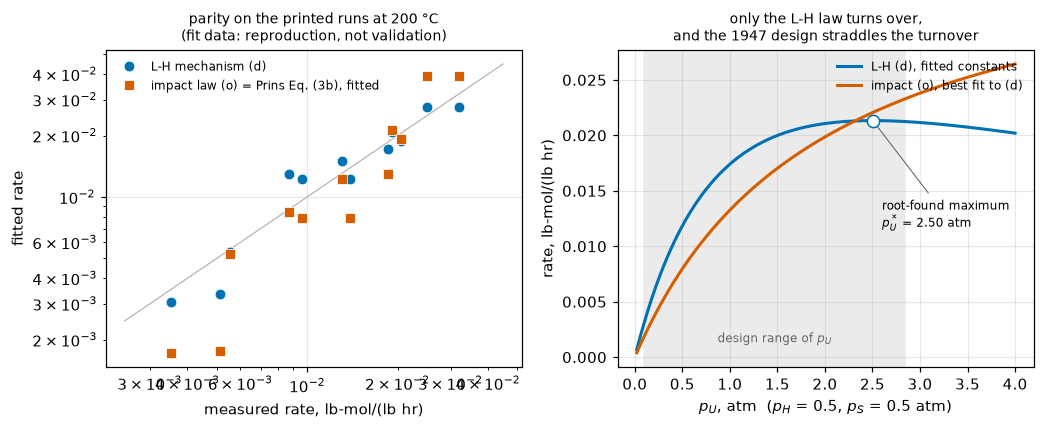

The codimer instantiation closes the loop on Section 3: the L-H maximum sits at
$p_U^* = 2.50$ atm (`find_roots` on $p_U \in [0.02, 40]$ with exactly one root, the closed form
agreeing to 1e-11 and pymrm's `newton` to 1e-10) at $p_H = p_S = 0.5$ atm, **inside the 1947
design range** ($p_U$ from 0.10 to 2.84 atm, the root a fraction 0.13 of $p_U^*$ from the nearer
end). The impact law is monotone in every partial pressure; a design that straddles the turnover is
exactly a design that can see the difference.

In [14]:
# Figure 3: the fits on the measured runs, and the L-H maximum in p_U.
pH0, pS0 = 0.5, 0.5
pUstar = claims["codimer_pUstar_atm"]
r_d = rate_d(cd0, H, U, S)
r_exact = rate_d(cd0, H, U, S)
po_meas = fit_form("o", H, U, S, robs)[0]
po_gen = fit_form("o", H, U, S, r_exact)[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
ax1.loglog(robs, r_d, "o", ms=7, color=COL["lh"], mec="white", mew=0.5, label="L-H mechanism (d)")
ax1.loglog(robs, FORMS["o"][1](po_meas, H, U, S), "s", ms=7, color=COL["lr"], mec="white", mew=0.5,
           label="impact law (o) = Prins Eq. (3b), fitted")
lo, hi = 0.7 * robs.min(), 1.4 * robs.max()
ax1.plot([lo, hi], [lo, hi], color="0.7", lw=0.8, zorder=0)
ax1.set_xlabel("measured rate, lb-mol/(lb hr)"); ax1.set_ylabel("fitted rate")
ax1.set_title("parity on the printed runs at 200 °C\n(fit data: reproduction, not validation)", fontsize=9)
ax1.legend(frameon=False, fontsize=8)
pUg = np.linspace(0.02, 4.0, 400)
r_lh_pU = rate_d(cd0, pH0, pUg, pS0)
r_lr_pU = FORMS["o"][1](po_gen, np.full_like(pUg, pH0), pUg, np.full_like(pUg, pS0))
ax2.plot(pUg, r_lh_pU, color=COL["lh"], lw=2, label="L-H (d), fitted constants")
ax2.plot(pUg, r_lr_pU, color=COL["lr"], lw=2, label="impact (o), best fit to (d)")
r_at_star = float(rate_d(cd0, pH0, pUstar, pS0))       # the rate at the root, evaluated, not read off the grid
ax2.plot([pUstar], [r_at_star], "o", ms=8, color=COL["lh"], mfc="white", zorder=5)
ax2.annotate(f"root-found maximum\n$p_U^*$ = {pUstar:.2f} atm", xy=(pUstar, r_at_star),
             xytext=(2.6, 0.55 * r_lh_pU.max()), fontsize=8,
             arrowprops=dict(arrowstyle="-", lw=0.7, color="0.4"))
ax2.axvspan(U.min(), U.max(), color="0.92", zorder=0)
ax2.text(0.5 * (U.min() + U.max()), 0.06 * r_lh_pU.max(), "design range of $p_U$",
         fontsize=8, color="0.4", ha="center")
ax2.set_xlabel("$p_U$, atm  ($p_H$ = %.1f, $p_S$ = %.1f atm)" % (pH0, pS0))
ax2.set_ylabel("rate, lb-mol/(lb hr)")
ax2.set_title("only the L-H law turns over,\nand the 1947 design straddles the turnover", fontsize=9)
ax2.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout(); plt.show()

say("""The codimer instantiation closes the loop on Section 3: the L-H maximum sits at
$p_U^* = @@p@@$ atm (`find_roots` on $p_U \\in [0.02, 40]$ with exactly one root, the closed form
agreeing to @@g1@@ and pymrm's `newton` to @@g2@@) at $p_H = p_S = @@ph@@$ atm, **@@ins@@ the 1947
design range** ($p_U$ from @@u0@@ to @@u1@@ atm, the root a fraction @@mg@@ of $p_U^*$ from the nearer
end). The impact law is monotone in every partial pressure; a design that straddles the turnover is
exactly a design that can see the difference.""",
    p=f"{pUstar:.2f}", g1=f"{claims['codimer_pUstar_vs_closed_rel']:.0e}",
    g2=f"{claims['codimer_pUstar_newton_rel']:.0e}", ph=pH0,
    ins="inside" if claims["pUstar_inside_design"] else "outside",
    u0=f"{U.min():.2f}", u1=f"{U.max():.2f}", mg=f"{CD['pUstar_margin_to_design_ends']:.2f}")

### 7. The paper's own numbers, checked

Two of the paper's printed quantitative statements are internally checkable,
and both check out; they are quantified here rather than left as "close" and
"very high". The inputs are rows of the page's CSV, and the helper takes the
inputs as arguments so the break table can enter a transcription slip.

In [15]:
def printed_checks(flux_slip=1.0, translational=None, binding=None):
    """The Mullins-Weinberg flux parity pressure and the HD energy budget, from the printed rows.
    ``flux_slip`` multiplies the printed L-R flux, ``translational`` and ``binding`` replace the
    printed translational energy and D-on-Cu binding energy."""
    v = P.value
    rate_per_atm = v["lr_flux_at_1atm"] * flux_slip / v["lr_flux_reference_pressure"]
    e_sum = (v["hd_mean_translational"] if translational is None else translational) \
        + v["hd_mean_rotational"] + v["hd_mean_vibrational"]
    e_exo = v["h2_dissociation_energy"] - (v["d_on_cu_binding_energy_about"] if binding is None else binding)
    return {"mw_parity_atm_low": v["lh_attempt_freq_low"] / rate_per_atm,
            "mw_parity_atm_high": v["lh_attempt_freq_high"] / rate_per_atm,
            "energy_sum_kJmol": e_sum, "energy_exo_kJmol": e_exo, "energy_ratio": e_sum / e_exo,
            "energy_shortfall_pct": 100 * (1 - e_sum / e_exo)}


PC_ = printed_checks()
for name, v in PC_.items():
    claims.value(name, v, rtol=1e-3)
brk_moved("printed L-R flux mistyped with a factor 10", printed_checks(flux_slip=10.0))
TRANS_SLIP = 28
brk_moved(f"translational energy mistyped as {TRANS_SLIP} (digits transposed)",
          printed_checks(translational=TRANS_SLIP))
brk_moved("D-on-Cu binding energy read as 420", printed_checks(binding=420))

say("""**"Very high pressures", quantified:** the printed L-H attempt frequencies against the printed L-R
collision flux put flux parity at **@@lo@@ to @@hi@@ atm**, the arithmetic behind the paper's "very high
pressures are required to make the L-R mechanism compatible with the L-H mechanism".

**"Close to", quantified:** the HD product's printed translational, rotational and vibrational
energies sum to **@@s@@ kJ/mol** against an exothermicity of **@@e@@ kJ/mol**: a ratio of **@@r@@**, so
the sum is about @@sf@@ % below it, consistent with the paper's "close to the exothermicity" and with
the "about" on the binding energy.""",
    lo=f"{claims['mw_parity_atm_low']:.0f}", hi=f"{claims['mw_parity_atm_high']:.0f}",
    s=f"{claims['energy_sum_kJmol']:.0f}", e=f"{claims['energy_exo_kJmol']:.0f}",
    r=f"{claims['energy_ratio']:.3f}", sf=f"{claims['energy_shortfall_pct']:.0f}")

**"Very high pressures", quantified:** the printed L-H attempt frequencies against the printed L-R
collision flux put flux parity at **1000 to 10000 atm**, the arithmetic behind the paper's "very high
pressures are required to make the L-R mechanism compatible with the L-H mechanism".

**"Close to", quantified:** the HD product's printed translational, rotational and vibrational
energies sum to **176 kJ/mol** against an exothermicity of **196 kJ/mol**: a ratio of **0.898**, so
the sum is about 10 % below it, consistent with the paper's "close to the exothermicity" and with
the "about" on the binding energy.

## Validation

**What validation can mean here.** The source prints no measurement, so
nothing on this page is experimental validation and nothing is presented as
such. The checks are: (i) symbolic derivation of every printed limit from the
paper's own equations (Section 1); (ii) independent double computation of every
headline, the L-H maximum by closed form against a root of the NumPy-coded law
by `find_roots` and by `newton`, $w^*$ by two optimizer routes plus a grid
refinement, the impact-law misfit by two optimizer families; (iii)
reconciliation of every imported `C1.1` number against the book's own printed
Table C and against `C1.1`'s published claims, which independently reproduced
`C1.1`'s run-25a digit-slip finding; and (iv) the defect-injection table below,
in which every claim is moved by a deliberate defect entered through a call
argument.

**Blind spots, declared.** The two $w^*$ routes share the metric's *definition*
(grid, norm, noiseless generator): they guard the search, not the definition,
and the norm-dependence is quantified in its break row. The `find_roots` and
`newton` routes share the objective, so they cross-check the root finder, not the
law. The symbolic identities are exact by algebra and can catch only a
transcription slip in their own cell, each carrying a companion that can fail. The
impact-law conclusions are conditional on mechanism (d) being the true generator,
which is itself only the book's accepted fit; that is why every codimer number is
labelled a numerical experiment on fit data. The paired fit-quality comparison on
the measured runs is not resolved at two standard errors, and nothing is concluded
from it.

In [16]:
bt = pd.DataFrame(BREAK, columns=["injected defect", "claim", "clean value", "with the defect", "fails its check"])
is_bound = bt["claim"].map(lambda n: claims.metrics[n]["kind"] == "bound")
fmt = lambda v: f"{v:.4g}" if isinstance(v, (float, np.floating)) else str(v)
# a bound's clean value is round-off or solver-tolerance level and differs between machines: print one digit
bt["clean value"] = [f"(here {v:.0e})" if b else fmt(v) for v, b in zip(bt["clean value"], is_bound)]
bt["with the defect"] = [f"{v:.2g}" if b else fmt(v) for v, b in zip(bt["with the defect"], is_bound)]
print(bt.to_string(index=False, max_colwidth=70))
print(f"\n{len(bt)} break rows defined, all printed; {int(bt['fails its check'].sum())} fail their claim's "
      f"own check; {len(claims.metrics)} claims registered.")

                                                       injected defect                               claim  clean value with the defect  fails its check
                                  block read at 275 C instead of 200 C                        runs_at_200C           12              13             True
                                 printed order_A_LH_high entered as +1                printed_limits_agree           11              10             True
                                       exponent of Eq. (3a) taken as 1                printed_limits_agree           11               9             True
                                          power of Eq. (3b) taken as 2                printed_limits_agree           11               9             True
                       candidate K_A c_A = 1, the reduced-form reading        max_condition_is_1_plus_KBcB         True           False             True
                                       exponent of Eq. (3a) taken as 1        max_

## What pymrm adds

**To the rate laws themselves, nothing, and this page does not pretend
otherwise.** No operator is assembled and no transport equation is solved: the
laws, the limits, the fits and the comparisons are NumPy, SciPy and sympy. What
pymrm contributes is two scalar root-finding tools and only those.
`pymrm.checks.find_roots` locates every extremum and threshold on the page on its
physical range (the maximum of the L-H law, the maximum in $p_U$ of the fitted
codimer law and the window spans $w^*$ at three tolerances), scanning the whole
range and refining every sign change, so a defect that leaves no root or two raises
instead of returning a number. `newton` on a `NumJac((1, 1))` Jacobian is the
independent route for the two maxima, its `success` checked and its agreement with
the `find_roots` root a bound. The page's own contributions are the identifiability
window $w^*$, the unit-invariance test of the printed maximum condition and the
impact-law power study, each labelled as the page's own where it appears; the L-H
law and its constants are imported from `C1.1`, not re-derived.

## Reuse

- **The impact (E-R/L-R) rate closure**, ready for any pymrm reactor page:
  $r = k'K_Ac_Ac_B/(1+K_Ac_A + \dots)$. The colliding species appears in the
  numerator only; every *adsorbed* species (including products) appears in the
  first-power adsorption group. Do not add the colliding species to the
  denominator: Section 6 shows that single term is the entire identifiable
  difference from L-H on a realistic design.
- **Naming, for any page that cites this mechanism:** the source argues the
  collision mechanism is Langmuir's (1922) and that the IUPAC-defined name is
  Langmuir-Rideal; what Eley and Rideal studied was a chemisorbed +
  *physisorbed* pair. This page keeps "Eley-Rideal" in its title because that is
  the catalogue's and the literature's name, and reports the attribution finding
  rather than adjudicating primary literature it has not read.
- **Designing a discrimination experiment:** vary the concentration of the
  *non-adsorbing* candidate over at least a decade **and place the window to
  straddle the suspected L-H maximum** ($K_Ac_A^* = 1 + K_Bc_B$, not the printed
  "$c_A = K_A$"). Width without curvature buys nothing (Section 5's break row); a
  span of the colliding partner below $w^*$ cannot reject the impact law at the
  book's own fit precision even with noiseless data (Section 6's collapsed-design
  row).
- **What this page cannot support:** any claim of experimental validation of
  either rate law, because the source prints no data, and any claim about what
  Langmuir, Rideal, Eley, or the IUPAC Gold Book actually wrote beyond what Prins
  (2018) quotes of them; those originals are recorded as `origin_not_consulted` in
  `meta.yaml`.
- **Related pages:** `C1.1` (the L-H law and the codimer data), `C1.3`
  (Mars-van Krevelen, Langmuir's second mechanism), `J1.1` (the Langmuir
  isotherm), `B1.4` and `H1.1` (the same finding class).

In [17]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C1.2:
  runs_at_200C                        = 12               exact  exact
  printed_limits_agree                = 11               exact  exact
  max_condition_is_1_plus_KBcB        = True             exact  exact
  orderB_gap_closed_form              = True             exact  exact
  p715_rhs_is_net_rate                = True             exact  exact
  p715_rhs_is_three_term_form         = True             exact  exact
  p715_equilibrium_residual           = (here 4.9e-16)   bound  bound <= 1e-12 [identity]
  orderA_LH_slope_at_x1e4             = -0.99979         value  rtol 0.001
  orderA_LH_slope_at_x1em4            = 0.99981          value  rtol 0.001
  orderA_LR_slope_at_x1e4             = 9.999e-05        value  rtol 0.001
  orderA_LR_slope_at_x1em4            = 0.9999           value  rtol 0.001
  orderAB_LH_slope_at_x1e4            = 0.00019998       value  rtol 0.001
  orderAB_LR_slope_at_x1e4            = 1.0001           value  rtol 0.001
  fd_slope_h_refinement